<a href="https://colab.research.google.com/github/Noelsip/final-task/blob/main/Tugas_Akhir_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Pengaruh *Cyclical Learning Rate* terhadap Model CNN dalam Klasifikasi Citra Sintetis AI

**Dataset:** CIFAKE
****
**Kelas:** REAL dan FAKE

**Model:** *Covolution Neural Network*

**Strategi Learning Rate:** *Fixed Learning Rate* dan *Cyclical Learning Rate*

## Instalasi Pustaka

In [1]:
import os
import gc
import math
import random
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Library Berhasil dimuat.")
print("TensorFlow : ", tf.__version__)
print("Numpy      : ", np.__version__)
print("Pandas     : ", pd.__version__)

Library Berhasil dimuat.
TensorFlow :  2.20.0
Numpy      :  2.1.3
Pandas     :  2.2.3


# Lingkungan Eksperimen

In [43]:
# Mengimpor modul sistem Python.
import sys

# Mengimpor modul informasi sistem.
import platform

# Mengambil daftar GPU yang tersedia.
gpu_devices = tf.config.list_physical_devices("GPU")

# Mengambil informasi GPU dari NVIDIA.
gpu_info = os.popen(
    "nvidia-smi --query-gpu=name,memory.total "
    "--format=csv,noheader"
).read().strip()

# Menampilkan judul lingkungan eksperimen.
print("LINGKUNGAN EKSPERIMEN\n")

# Menampilkan platform penelitian.
print("Platform           : Google Colaboratory")

# Menampilkan informasi prosesor.
print(
    f"Prosesor           : "
    f"{platform.processor()}"
)

# Menampilkan informasi GPU.
print(
    f"GPU                : "
    f"{gpu_info if gpu_info else 'Tidak terdeteksi'}"
)

# Menampilkan informasi RAM sistem.
ram_info = os.popen("free -h").read()

# Menampilkan informasi RAM.
print("\nInformasi RAM:")
print(ram_info)

# Menampilkan versi Python.
print(
    f"Python             : "
    f"{sys.version.split()[0]}"
)

# Menampilkan versi TensorFlow.
print(
    f"TensorFlow         : "
    f"{tf.__version__}"
)

# Menampilkan versi NumPy.
print(
    f"NumPy              : "
    f"{np.__version__}"
)

# Menampilkan versi Pandas.
print(
    f"Pandas             : "
    f"{pd.__version__}"
)

# Menampilkan versi Matplotlib.
print(
    f"Matplotlib         : "
    f"{plt.matplotlib.__version__}"
)

# Mengimpor scikit-learn untuk mengambil versinya.
import sklearn

# Menampilkan versi scikit-learn.
print(
    f"scikit-learn       : "
    f"{sklearn.__version__}"
)

LINGKUNGAN EKSPERIMEN

Platform           : Google Colaboratory
Prosesor           : x86_64
GPU                : Tesla T4, 15360 MiB

Informasi RAM:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       3.6Gi       3.0Gi       524Mi       6.9Gi       9.1Gi
Swap:             0B          0B          0B

Python             : 3.13.15
TensorFlow         : 2.20.0
NumPy              : 2.1.3
Pandas             : 2.2.3
Matplotlib         : 3.10.0
scikit-learn       : 1.6.1


## Konfigurasi Eksperimen dan Reproducibility

In [2]:
SEED = 1

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
  tf.config.experimental.enable_op_determinism()
  DETERMINISTIC_ENABLED = True
except Exception as e:
  DETERMINISTIC_ENABLED = False
  print("Peringatan Determinism: ", e)

# Datase
DATASET_ROOT = Path("/content/cifake_data")
TRAIN_DIR = DATASET_ROOT / "train"
TEST_DIR = DATASET_ROOT / "test"

CLASS_NAMES = ["REAL" , "FAKE"]
CLASS_TO_LABEL = {
    "REAL": 0,
    "FAKE": 1
}

# Konfigurasi Citra
IMG_HEIGHT = 32
IMG_WIDTH = 32
IMG_CHANNELS = 3
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

# Data split
VAL_RATIO = 0.10

# Konfigurasi Pelatihan
BATCH_SIZE = 32
EPOCHS = 50

# Fix Learning Rate
FIXED_LR = 1e-3

# Learning Rate Range Test
LRRT_START = 1e-7
LRRT_END = 1e-1
LRRT_EPOCHS = 5

# Cyclical Learning Rate
STEP_SIZE_MULTIPLIER = 5

BASE_LR = None
MAX_LR = None

# Hasil Eksperimen
RESULTS_DIR = Path("/content/results")
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"

print("KONFIGURASI EKSPERIMEN")
print(f"Seed                  : {SEED}")
print(f"Determinism           : {DETERMINISTIC_ENABLED}")
print(f"Image size            : {IMG_SIZE} x {IMG_CHANNELS} channel")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Epoch                 : {EPOCHS}")
print(f"Fixed learning rate   : {FIXED_LR}")
print(f"LRRT start            : {LRRT_START:.1e}")
print(f"LRRT end              : {LRRT_END:.1e}")
print(f"LRRT epochs           : {LRRT_EPOCHS}")
print(f"CLR step multiplier   : {STEP_SIZE_MULTIPLIER}")

KONFIGURASI EKSPERIMEN
Seed                  : 1
Determinism           : True
Image size            : (32, 32) x 3 channel
Batch size            : 32
Epoch                 : 50
Fixed learning rate   : 0.001
LRRT start            : 1.0e-07
LRRT end              : 1.0e-01
LRRT epochs           : 5
CLR step multiplier   : 5


# Pengambilan Dataset



Dataset yang digunakan adalah CIFAKE yang terdiri atas citra REAL dan FAKE

Dataset penelitian mempertahankan:
- 100.000 citra untuk bagian training awal
- 20.000 citra untuk testing

Bagian training kemudian dibagi menjadi:
- 90.000 citra training
- 10.000 citra validation

Pembagian dilakukan secara eksplisit per kelas agar komposisinya tetap seimbang.

## Upload kaggle.json

In [3]:
import os
from google.colab import files

print("Silahkan upload file kaggle.json")
uploaded = files.upload()

# Memeriksa jika ada file kaggle yang diupload (bisa berupa kaggle (1).json, dll)
uploaded_kaggle_file = None
for filename in uploaded.keys():
  if filename.startswith("kaggle") and filename.endswith(".json"):
    uploaded_kaggle_file = filename
    break

if not uploaded_kaggle_file:
  raise FileNotFoundError(
      "File kaggle.json tidak ditemukan",
      "Upload file kaggle.json!!!"
  )

# Jika file terupload dengan nama duplikat, rename menjadi kaggle.json
if uploaded_kaggle_file != "kaggle.json":
  if os.path.exists("kaggle.json"):
    os.remove("kaggle.json")
  os.rename(uploaded_kaggle_file, "kaggle.json")

print("kaggle.json berhasil diupload dan disiapkan!")

Silahkan upload file kaggle.json


Saving kaggle.json to kaggle.json
kaggle.json berhasil diupload dan disiapkan!


## Download dan Ekstrak CIFAKE

In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download Dataset
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images

# Ekstraksi Dataset
!rm -rf /content/cifake_data
!mkdir -p /content/cifake_data

!unzip -q cifake-real-and-ai-generated-synthetic-images.zip -d /content/cifake_data

print("Dataset berhasil diunduh dan diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 137MB/s] 

Dataset berhasil diunduh dan diekstrak.


## Verifikasi Dataset CIFAKE

In [5]:
VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".gif"
}

def count_images(folder):
    folder = Path(folder)

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


def count_class_images(folder, class_name):
    class_dir = Path(folder) / class_name

    if not class_dir.exists():
        return 0

    return sum(
        1
        for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


print("STRUKTUR DATASET")

print("\nTrain directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TRAIN_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TRAIN_DIR):,} images"
)

print("\nTest directory:")
for class_name in CLASS_NAMES:
    print(
        f"{class_name:>5} : "
        f"{count_class_images(TEST_DIR, class_name):,} images"
    )

print(
    f"TOTAL : {count_images(TEST_DIR):,} images"
)


STRUKTUR DATASET

Train directory:
 REAL : 50,000 images
 FAKE : 50,000 images
TOTAL : 100,000 images

Test directory:
 REAL : 10,000 images
 FAKE : 10,000 images
TOTAL : 20,000 images


## Pembagian Train dan Validation

In [6]:

def collect_class_paths(root_dir, class_name):
  class_dir = Path(root_dir) / class_name

  paths = sorted([
      p
      for p in class_dir.rglob("*")
      if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
  ])
  return paths

train_paths = []
train_labels = []

val_paths = []
val_labels = []

rng = np.random.default_rng(SEED)

print("PEMBAGIAN TRAIN / VALIDATION")
print()

for class_name in CLASS_NAMES:
  label = CLASS_TO_LABEL[class_name]

  class_paths = collect_class_paths(TRAIN_DIR, class_name)

  if len(class_paths) == 0:
    raise RuntimeError(f"Tidak ada file ditemukan untuk kelas {class_name}")

  # menggunakan shuffle untuk menentukan split
  rng.shuffle(class_paths)

  n_validation = int(len(class_paths) * VAL_RATIO)

  class_val_paths = class_paths[:n_validation]
  class_train_paths = class_paths[n_validation:]

  train_paths.extend(class_train_paths)
  train_labels.extend([label] * len(class_train_paths))

  val_paths.extend(class_val_paths)
  val_labels.extend([label] * len(class_val_paths))

  print(f"\nKelas {class_name}")
  print(f"Total       : {len(class_paths):,}")
  print(f"Training    : {len(class_train_paths):,}")
  print(f"Validation  : {len(class_val_paths):,}")

# Mengonversi ke NumPy
train_paths = np.array([str(p) for p in train_paths])

train_labels = np.array(train_labels, dtype=np.float32)

val_paths = np.array([str(p) for p in val_paths])

val_labels = np.array(val_labels, dtype=np.float32)

# Membuat test tetap utuh
test_paths = []
test_labels = []

for class_name in CLASS_NAMES:
    label = CLASS_TO_LABEL[class_name]

    class_paths = collect_class_paths(TEST_DIR, class_name)

    test_paths.extend([str(p) for p in class_paths])

    test_labels.extend([label] * len(class_paths))


test_paths = np.array(test_paths)
test_labels = np.array(
    test_labels,
    dtype=np.float32
)

print("HASIL AKHIR SPLIT\n")

print(f"Training    : {len(train_paths):,}")
print(f"Validation  : {len(val_paths):,}")
print(f"Testing     : {len(test_paths):,}")

PEMBAGIAN TRAIN / VALIDATION


Kelas REAL
Total       : 50,000
Training    : 45,000
Validation  : 5,000

Kelas FAKE
Total       : 50,000
Training    : 45,000
Validation  : 5,000
HASIL AKHIR SPLIT

Training    : 90,000
Validation  : 10,000
Testing     : 20,000


## Data Pipeline

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_and_rescale(path, label):

  # Membaca file gambar menjadi bytes
  image_bytes = tf.io.read_file(path)

  # Decode bytes menjadi tensor gambar
  image_tensor = tf.io.decode_image(
      image_bytes,
      channels=IMG_CHANNELS,
      expand_animations=False
  )

  # Memastikan ukuran dan jumlah channel sesuai
  image_tensor = tf.ensure_shape(
      image_tensor,
      [IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS]
  )

  # Konversi tensor ke float32 dan normalisasi ke 0-1
  image_array = tf.cast(
      image_tensor,
      tf.float32
  ) / 255.0

  # Memastikan label bertipe float32
  label = tf.cast(
      label,
      tf.float32
  )

  return image_array, label

# Membuat dataset dengan pipeline
def make_dataset(
    paths,
    labels,
    shuffle=False,
    seed=None,
    cache=False
):
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))

  if shuffle:
    ds = ds.shuffle(
        buffer_size=len(paths),
        seed=seed,
        reshuffle_each_iteration=True
    )

  options = tf.data.Options()
  options.experimental_deterministic = True
  ds = ds.with_options(options)

  ds = ds.map(decode_and_rescale, num_parallel_calls=AUTOTUNE)
  ds = ds.batch(BATCH_SIZE, drop_remainder=False)

  if cache:
    ds = ds.cache()

  ds = ds.prefetch(AUTOTUNE)

  return ds

# Dataset awal inspeksi
train_ds = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

val_ds = make_dataset(
    val_paths,
    val_labels,
    shuffle=False,
    cache=True
)

test_ds = make_dataset(
    test_paths,
    test_labels,
    shuffle=False,
    cache=True
)

STEPS_PER_EPOCH = math.ceil(
    len(train_paths) / BATCH_SIZE
)

print("DATA PIPELINE\n")
print(f"Training samples : {len(train_paths):,}")
print(f"Validation       : {len(val_paths):,}")
print(f"Testing          : {len(test_paths):,}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Steps / epoch    : {STEPS_PER_EPOCH:,}")

DATA PIPELINE

Training samples : 90,000
Validation       : 10,000
Testing          : 20,000
Batch size       : 32
Steps / epoch    : 2,813


## Verifikasi Jumlah dan Distribusi Kelas

In [8]:
def summarize_labels(labels, split_name):
  labels_int = labels.astype(int)

  real_count = np.sum(labels_int == CLASS_TO_LABEL["REAL"])

  fake_count = np.sum(labels_int == CLASS_TO_LABEL["FAKE"])

  return {
      "Split": split_name,
      "REAL": real_count,
      "FAKE": fake_count,
      "Total": len(labels_int)
  }

dataset_summary = pd.DataFrame([
    summarize_labels(
        train_labels,
        "Training"
    ),
    summarize_labels(
        val_labels,
        "Validation"
    ),
    summarize_labels(
        test_labels,
        "Testing"
    )
])

display(dataset_summary)

# Validasi eksplisit
assert len(train_paths) == 90000
assert len(val_paths) == 10000
assert len(test_paths) == 20000

assert np.sum(train_labels == 0) == 45000
assert np.sum(train_labels == 1) == 45000

assert np.sum(val_labels == 0) == 5000
assert np.sum(val_labels == 1) == 5000

assert np.sum(test_labels == 0) == 10000
assert np.sum(test_labels == 1) == 10000

print("Semua validasi distribusi dataset berhasil.")

,Split,REAL,FAKE,Total
0,Training,45000,45000,90000
1,Validation,5000,5000,10000
2,Testing,10000,10000,20000


Semua validasi distribusi dataset berhasil.


## Visualisasi Sample Dataset

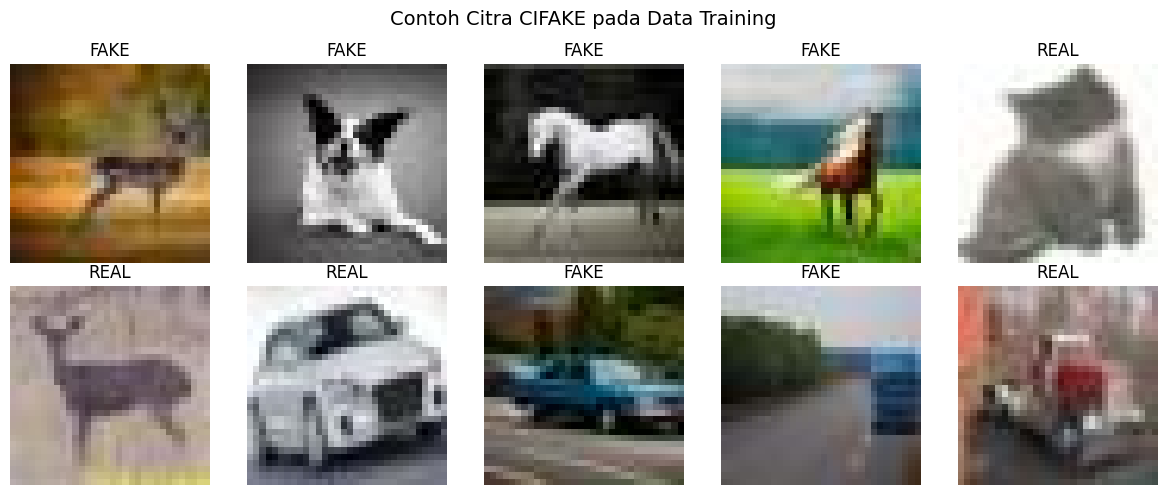

In [9]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].numpy())

    label = CLASS_NAMES[int(labels[i].numpy())]

    plt.title(label)
    plt.axis("off")

plt.suptitle(
    "Contoh Citra CIFAKE pada Data Training",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Model CNN



Model CNN digunakan untuk melakukan klasifikasi biner antara citra REAL dan FAKE.

Arsitektur yang digunakan mengikuti rancangan penelitian:

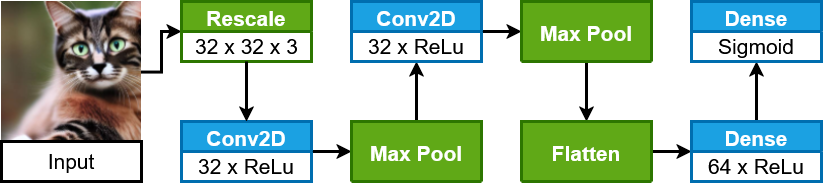

Optimizer:
Adam

Loss function:
Binary Cross Entropy

## Membangun CNN

In [10]:
from prompt_toolkit import filters
def build_model(seed=SEED):
  # Melakukan reset state sebelum membangun model
  tf.keras.utils.set_random_seed(seed)

  model = tf.keras.Sequential(
      [
          tf.keras.layers.Input(
              shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)
          ),

          # Conv Block 1
          tf.keras.layers.Conv2D(
              filters=32,
              kernel_size=(3, 3),
              activation="relu",
              name="conv2d_1"
          ),

          tf.keras.layers.MaxPooling2D(
              pool_size=(2, 2),
              name="maxpool_1"
          ),

          # Conv Block 2
          tf.keras.layers.Conv2D(
              filters=32,
              kernel_size=(3, 3),
              activation="relu",
              name="conv2d_2"
          ),

          tf.keras.layers.MaxPooling2D(
              pool_size=(2, 2),
              name="maxpool_2"
          ),

          # Classification
          tf.keras.layers.Flatten(
              name="flatten"
          ),

          tf.keras.layers.Dense(
              64,
              activation="relu",
              name="dense_64"
          ),

          tf.keras.layers.Dense(
              1,
              activation="sigmoid",
              name="output"
          )
      ],
      name="cnn_cifake"
  )

  return model

model = build_model()

print("Model Berhasil Dibangun")

Model Berhasil Dibangun


## Verifikasi Arsitektur CNN

In [11]:
model.summary()

print("\nJumlah Parameter Total: ")
print(f"{model.count_params():,}")

print("\nVerifikasi Arsitektur Berhasil")

Model: "cnn_cifake"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_1 (MaxPooling2D)        │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling2D)        │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,001 (328.13 KB)

 Trainable params: 84,001 (328.13 KB)

 Non-trainable params: 0 (0.00 B)


Jumlah Parameter Total: 
84,001

Verifikasi Arsitektur Berhasil


## Utility Evaluasi Model

In [12]:
# Membuat fungsi untuk mengambil label dan prediksi dari seluruh dataset.
def predict_dataset(model, dataset):

    # Mengambil seluruh label aktual dari dataset.
    y_true = np.concatenate([
        labels.numpy().astype(int).ravel()
        for _, labels in dataset
    ])

    # Menghasilkan probabilitas prediksi model.
    y_prob = model.predict(
        dataset,
        verbose=0
    ).ravel()

    # Mengubah probabilitas menjadi kelas menggunakan threshold 0.5.
    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    # Mengembalikan label aktual, probabilitas, dan prediksi.
    return y_true, y_prob, y_pred


# Membuat fungsi untuk mengevaluasi model.
def evaluate_model(model, dataset, split_name="Test"):

    # Mengevaluasi loss dan accuracy pada dataset.
    evaluation = model.evaluate(
        dataset,
        verbose=0,
        return_dict=True
    )

    # Mengambil label aktual dan prediksi model.
    y_true, y_prob, y_pred = predict_dataset(
        model,
        dataset
    )

    # Menghitung precision.
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung recall.
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung F1-score.
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # Menghitung confusion matrix.
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # Menghitung classification report.
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    # Mengubah classification report menjadi DataFrame.
    report_df = pd.DataFrame(report_dict).T

    # Menyimpan seluruh hasil evaluasi.
    results = {
        "Split": split_name,
        "Loss": float(evaluation["loss"]),
        "Accuracy": float(evaluation["accuracy"]),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-score": float(f1),
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
        "confusion_matrix": cm,
        "classification_report": report_df
    }

    # Mengembalikan hasil evaluasi.
    return results


# Membuat fungsi untuk menentukan epoch terbaik.
def get_best_epoch(history):

    # Mengambil validation loss.
    val_loss = np.array(
        history.history["val_loss"]
    )

    # Mengambil validation accuracy.
    val_accuracy = np.array(
        history.history["val_accuracy"]
    )

    # Menentukan epoch dengan validation loss minimum.
    best_loss_epoch = int(
        np.argmin(val_loss) + 1
    )

    # Menentukan epoch dengan validation accuracy maksimum.
    best_accuracy_epoch = int(
        np.argmax(val_accuracy) + 1
    )

    # Mengembalikan kedua epoch.
    return (
        best_loss_epoch,
        best_accuracy_epoch
    )

# Konfigurasi *Learning Rate Range Test*



Learning Rate Range Test digunakan untuk memperoleh rentang learning rate yang
akan digunakan oleh Cyclical Learning Rate.

Rancangan:

- Start learning rate = 1e-10
- End learning rate = 1e-1
- Durasi = 5 epoch
- Kenaikan learning rate dilakukan secara eksponensial melalui faktor pengali q.
- Loss dicatat pada setiap batch.

Hasil pengujian kemudian digunakan untuk menentukan:
- base_lr
- max_lr

## Menjalankan Learning Rate Range Test

In [13]:
# Membersihkan session TensorFlow sebelumnya.
tf.keras.backend.clear_session()

# Mengatur ulang random seed untuk reproduksibilitas LRRT.
tf.keras.utils.set_random_seed(SEED)

# Memastikan direktori hasil tersedia.
RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Membuat dataset khusus LRRT.
train_ds_lrrt = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Menghitung jumlah step dalam satu epoch.
steps_per_epoch = math.ceil(
    len(train_paths) / BATCH_SIZE
)

# Menghitung total step LRRT.
N = LRRT_EPOCHS * steps_per_epoch

# Memastikan jumlah step mencukupi.
if N < 2:
    raise RuntimeError(
        "Jumlah total step LRRT harus lebih dari 1."
    )

# Menghitung faktor pengali learning rate eksponensial.
q = (
    LRRT_END / LRRT_START
) ** (
    1 / (N - 1)
)

# Menampilkan konfigurasi LRRT.
print("LEARNING RATE RANGE TEST\n")
print(
    f"Start LR: {LRRT_START:.2e}"
)
print(
    f"End LR: {LRRT_END:.2e}"
)
print(
    f"Epoch: {LRRT_EPOCHS}"
)
print(
    f"Steps / epoch: {steps_per_epoch:,}"
)
print(
    f"Total steps (N): {N:,}"
)
print(
    f"Multiplier (q): {q:.10f}"
)

# Membuat model khusus untuk LRRT.
model_lrrt = build_model(
    seed=SEED
)

# Membuat optimizer Adam untuk LRRT.
optimizer_lrrt = tf.keras.optimizers.Adam(
    learning_rate=LRRT_START
)

# Membuat fungsi Binary Cross Entropy.
bce_loss = tf.keras.losses.BinaryCrossentropy()

# Membuat list untuk menyimpan learning rate.
lr_values = []

# Membuat list untuk menyimpan raw loss.
raw_loss_values = []

# Membuat list untuk menyimpan smoothed loss.
smooth_loss_values = []

# Membuat list untuk menyimpan accuracy.
accuracy_values = []

# Menentukan faktor exponential moving average.
beta = 0.98

# Menginisialisasi nilai moving average loss.
avg_loss = 0.0

# Menginisialisasi penghitung global step.
global_step = 0

# Membuat list ringkasan loss setiap epoch.
epoch_loss_summary = []

# Membuat list ringkasan accuracy setiap epoch.
epoch_accuracy_summary = []

# Menandai kondisi berhentinya LRRT.
training_stopped = False

# Menampilkan awal proses LRRT.
print("\nMemulai Learning Rate Range Test...\n")

# Menjalankan LRRT sesuai jumlah epoch.
for epoch in range(LRRT_EPOCHS):

    # Membuat list loss untuk epoch saat ini.
    epoch_raw_losses = []

    # Membuat list accuracy untuk epoch saat ini.
    epoch_accuracies = []

    # Mengiterasikan seluruh batch training.
    for batch_images, batch_labels in train_ds_lrrt:

        # Menghitung learning rate pada global step saat ini.
        current_lr = (
            LRRT_START
            * (q ** global_step)
        )

        # Membatasi learning rate agar tidak melewati LRRT_END.
        current_lr = min(
            current_lr,
            LRRT_END
        )

        # Mengatur learning rate optimizer.
        optimizer_lrrt.learning_rate.assign(
            current_lr
        )

        # Mengubah bentuk label menjadi dua dimensi.
        batch_labels = tf.reshape(
            batch_labels,
            (-1, 1)
        )

        # Menghitung prediksi dan loss.
        with tf.GradientTape() as tape:

            # Menghasilkan prediksi model.
            predictions = model_lrrt(
                batch_images,
                training=True
            )

            # Menghitung Binary Cross Entropy.
            loss = bce_loss(
                batch_labels,
                predictions
            )

        # Menghitung gradien model.
        gradients = tape.gradient(
            loss,
            model_lrrt.trainable_variables
        )

        # Memperbarui bobot model menggunakan Adam.
        optimizer_lrrt.apply_gradients(
            zip(
                gradients,
                model_lrrt.trainable_variables
            )
        )

        # Mengubah loss menjadi nilai float.
        loss_value = float(
            loss.numpy()
        )

        # Menghentikan LRRT jika loss tidak finite.
        if not np.isfinite(loss_value):

            # Menampilkan lokasi terjadinya masalah.
            print(
                f"\nTraining dihentikan pada step "
                f"{global_step + 1} karena loss non-finite."
            )

            # Menandai LRRT berhenti.
            training_stopped = True

            # Menghentikan loop batch.
            break

        # Menghitung training accuracy batch.
        batch_accuracy = tf.reduce_mean(
            tf.cast(
                tf.equal(
                    tf.cast(
                        predictions >= 0.5,
                        tf.float32
                    ),
                    batch_labels
                ),
                tf.float32
            )
        )

        # Mengubah accuracy menjadi float.
        accuracy_value = float(
            batch_accuracy.numpy()
        )

        # Memperbarui exponential moving average loss.
        avg_loss = (
            beta * avg_loss
            + (1 - beta) * loss_value
        )

        # Mengoreksi bias pada moving average.
        smooth_loss = (
            avg_loss
            / (
                1
                - beta ** (global_step + 1)
            )
        )

        # Menyimpan learning rate.
        lr_values.append(
            current_lr
        )

        # Menyimpan raw loss.
        raw_loss_values.append(
            loss_value
        )

        # Menyimpan smoothed loss.
        smooth_loss_values.append(
            smooth_loss
        )

        # Menyimpan accuracy.
        accuracy_values.append(
            accuracy_value
        )

        # Menyimpan loss untuk ringkasan epoch.
        epoch_raw_losses.append(
            loss_value
        )

        # Menyimpan accuracy untuk ringkasan epoch.
        epoch_accuracies.append(
            accuracy_value
        )

        # Menambah global step.
        global_step += 1

    # Menyimpan ringkasan epoch jika data tersedia.
    if epoch_raw_losses:

        # Menghitung mean loss epoch.
        epoch_mean_loss = float(
            np.mean(epoch_raw_losses)
        )

        # Menghitung mean accuracy epoch.
        epoch_mean_accuracy = float(
            np.mean(epoch_accuracies)
        )

        # Menyimpan mean loss epoch.
        epoch_loss_summary.append(
            epoch_mean_loss
        )

        # Menyimpan mean accuracy epoch.
        epoch_accuracy_summary.append(
            epoch_mean_accuracy
        )

        # Menampilkan ringkasan epoch.
        print(
            f"Epoch {epoch + 1}/{LRRT_EPOCHS} "
            f"| mean loss = {epoch_mean_loss:.6f} "
            f"| accuracy = {epoch_mean_accuracy:.6f} "
            f"| last lr = {lr_values[-1]:.2e}"
        )

    # Menghentikan LRRT jika terjadi kondisi numerik.
    if training_stopped:
        break

# Mengubah learning rate menjadi NumPy array.
lr_values = np.asarray(
    lr_values,
    dtype=np.float64
)

# Mengubah raw loss menjadi NumPy array.
raw_loss_values = np.asarray(
    raw_loss_values,
    dtype=np.float64
)

# Mengubah smoothed loss menjadi NumPy array.
smooth_loss_values = np.asarray(
    smooth_loss_values,
    dtype=np.float64
)

# Mengubah accuracy menjadi NumPy array.
accuracy_values = np.asarray(
    accuracy_values,
    dtype=np.float64
)

# Memastikan LRRT menghasilkan data.
if len(lr_values) == 0:
    raise RuntimeError(
        "LRRT tidak menghasilkan observasi."
    )

# Membuat DataFrame hasil LRRT.
lrrt_df = pd.DataFrame({
    "learning_rate": lr_values,
    "raw_loss": raw_loss_values,
    "smoothed_loss": smooth_loss_values,
    "accuracy": accuracy_values
})

# Menentukan lokasi file hasil LRRT.
lrrt_path = (
    RESULTS_DIR
    / "learning_rate_range_test.csv"
)

# Menyimpan hasil LRRT.
lrrt_df.to_csv(
    lrrt_path,
    index=False
)

# Menampilkan ringkasan hasil LRRT.
print("\nHASIL LRRT\n")
print(
    f"Jumlah observasi       : {len(lr_values):,}"
)
print(
    f"LR aktual yang tersapu : "
    f"{lr_values.min():.2e} - {lr_values.max():.2e}"
)
print(
    f"Raw loss minimum       : "
    f"{raw_loss_values.min():.6f}"
)
print(
    f"Smoothed loss minimum  : "
    f"{smooth_loss_values.min():.6f}"
)
print(
    f"Accuracy maksimum      : "
    f"{accuracy_values.max():.6f}"
)
print(
    f"File hasil             : {lrrt_path}"
)

LEARNING RATE RANGE TEST

Start LR          : 1.00e-07
End LR            : 1.00e-01
Epoch             : 5
Steps / epoch     : 2,813
Total steps (N)   : 14,065
Multiplier (q)    : 1.0009828142

Memulai Learning Rate Range Test...

Epoch 1/5 | mean loss = 0.693096 | accuracy = 0.517630 | last lr = 1.58e-06
Epoch 2/5 | mean loss = 0.644884 | accuracy = 0.653539 | last lr = 2.51e-05
Epoch 3/5 | mean loss = 0.445947 | accuracy = 0.789726 | last lr = 3.98e-04
Epoch 4/5 | mean loss = 0.334273 | accuracy = 0.857070 | last lr = 6.31e-03
Epoch 5/5 | mean loss = 0.482861 | accuracy = 0.769908 | last lr = 1.00e-01

HASIL LRRT

Jumlah observasi       : 14,065
LR aktual yang tersapu : 1.00e-07 - 1.00e-01
Raw loss minimum       : 0.066499
Smoothed loss minimum  : 0.292809
Accuracy maksimum      : 1.000000
File hasil             : /content/results/learning_rate_range_test.csv


## Visualisasi Learning Rate Range Test

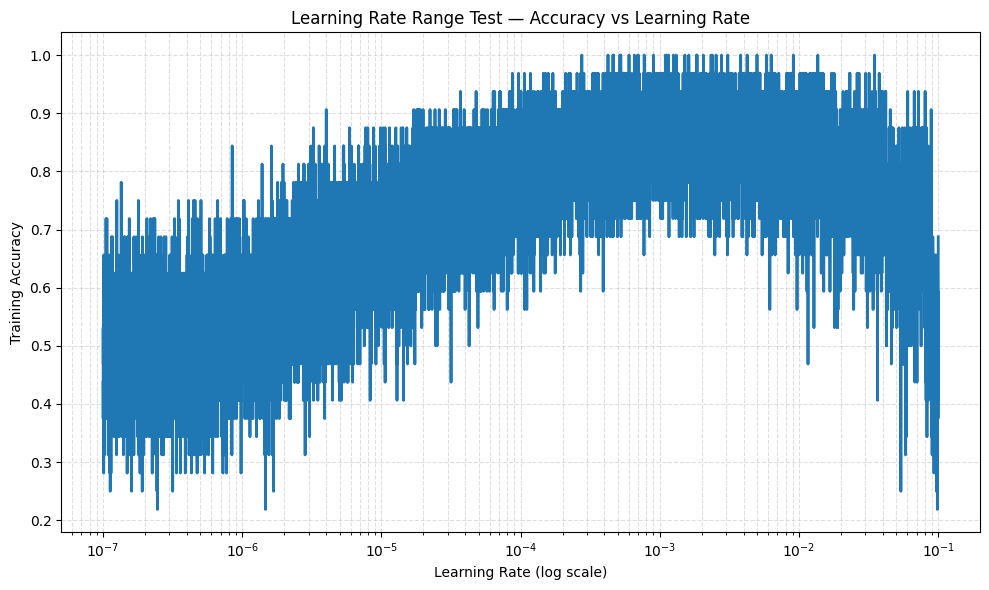

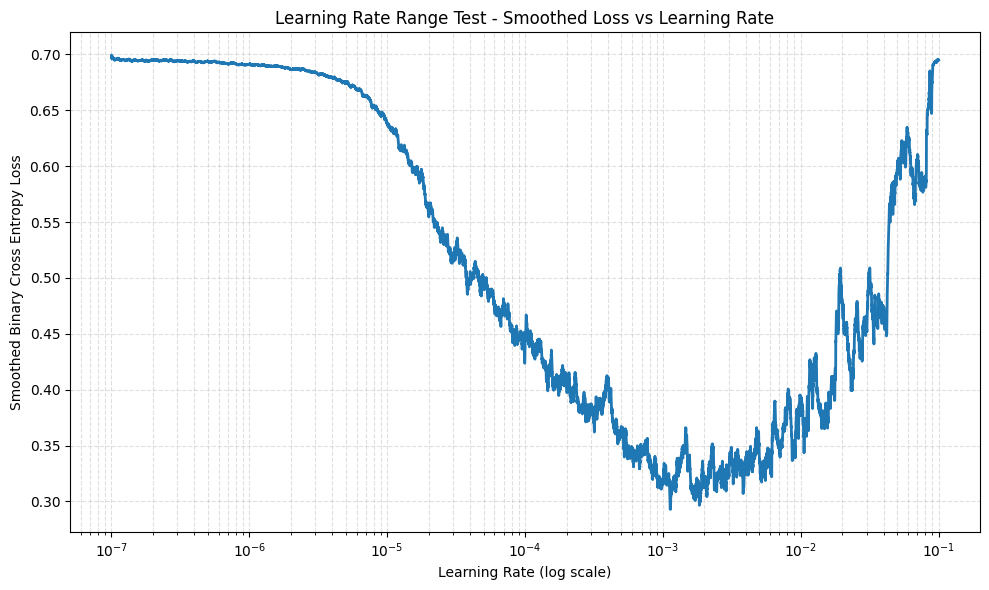

In [14]:
# Menyaring data LRRT yang valid.
valid_mask = (
    np.isfinite(lr_values)
    & np.isfinite(smooth_loss_values)
    & np.isfinite(accuracy_values)
)

# Mengambil learning rate yang valid.
plot_lr = lr_values[valid_mask]

# Mengambil smoothed loss yang valid.
plot_loss = smooth_loss_values[valid_mask]

# Mengambil accuracy yang valid.
plot_accuracy = accuracy_values[valid_mask]

# Membuat figure untuk grafik accuracy.
plt.figure(figsize=(10, 6))

# Menggambar accuracy terhadap learning rate.
plt.plot(
    plot_lr,
    plot_accuracy,
    linewidth=2
)

# Menggunakan skala logaritmik pada learning rate.
plt.xscale("log")

# Memberikan label sumbu learning rate.
plt.xlabel(
    "Learning Rate (log scale)"
)

# Memberikan label sumbu accuracy.
plt.ylabel(
    "Training Accuracy"
)

# Memberikan judul grafik.
plt.title(
    "Learning Rate Range Test — Accuracy vs Learning Rate"
)

# Menampilkan grid.
plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Membuat figure untuk grafik loss.
plt.figure(figsize=(10, 6))

# Menggambar smoothed loss terhadap learning rate.
plt.plot(
    plot_lr,
    plot_loss,
    linewidth=2
)

# Menggunakan skala logaritmik pada learning rate.
plt.xscale("log")

# Memberikan label sumbu learning rate.
plt.xlabel(
    "Learning Rate (log scale)"
)

# Memberikan label sumbu loss.
plt.ylabel(
    "Smoothed Binary Cross Entropy Loss"
)

# Memberikan judul grafik.
plt.title(
    "Learning Rate Range Test - Smoothed Loss vs Learning Rate"
)

# Menampilkan grid.
plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Menentukan Base LR dan Max LR

In [15]:
# Menyaring data LRRT yang valid.
valid_mask = (
    np.isfinite(lr_values)
    & np.isfinite(smooth_loss_values)
)

# Mengambil learning rate valid.
analysis_lr = lr_values[valid_mask]

# Mengambil smoothed loss valid.
analysis_loss = smooth_loss_values[valid_mask]

# Memastikan data LRRT mencukupi.
if len(analysis_loss) < 2:
    raise ValueError(
        "Data LRRT terlalu sedikit untuk menentukan learning rate."
    )

# Menentukan indeks minimum smoothed loss.
minimum_loss_index = int(
    np.argmin(analysis_loss)
)

# Mengambil learning rate pada minimum loss.
MINIMUM_LR = float(
    analysis_lr[minimum_loss_index]
)

# Mengambil nilai minimum loss.
MINIMUM_LOSS = float(
    analysis_loss[minimum_loss_index]
)

# Menentukan divergence factor untuk pemeriksaan kestabilan.
DIVERGENCE_FACTOR = 4.0

# Menghitung running best loss.
running_best_loss = np.minimum.accumulate(
    analysis_loss
)

# Menghitung batas divergence pada setiap titik.
divergence_limit = (
    DIVERGENCE_FACTOR
    * running_best_loss
)

# Menentukan titik loss yang telah mengalami divergence.
divergence_mask = (
    analysis_loss > divergence_limit
)

# Mengambil indeks divergence yang terdeteksi.
divergence_indices = np.flatnonzero(
    divergence_mask
)

# Menentukan indeks divergence pertama jika tersedia.
if len(divergence_indices) > 0:

    # Mengambil indeks divergence pertama.
    first_divergence_index = int(
        divergence_indices[0]
    )

else:

    # Menandai bahwa divergence tidak ditemukan.
    first_divergence_index = None

# Memastikan minimum loss terjadi sebelum divergence.
if (
    first_divergence_index is not None
    and minimum_loss_index
    >= first_divergence_index
):

    # Menolak hasil jika minimum loss terjadi setelah divergence.
    raise ValueError(
        "Minimum loss terjadi setelah divergence. "
        "Periksa kembali rentang LRRT."
    )

# Menentukan MAX_LR pada minimum smoothed loss.
MAX_LR = MINIMUM_LR

# Mengambil loss pada MAX_LR.
MAX_LOSS = MINIMUM_LOSS

# Menentukan BASE_LR secara manual menggunakan metode Smith.
BASE_LR = None

# Menampilkan hasil minimum loss yang digunakan sebagai MAX_LR.
print("HASIL PENENTUAN LEARNING RATE\n")

print(
    f"Learning Rate Minimum : "
    f"{MINIMUM_LR:.6e}"
)

print(
    f"Minimum Smoothed Loss : "
    f"{MINIMUM_LOSS:.6e}"
)

print(
    f"MAX_LR                : "
    f"{MAX_LR:.6e}"
)

# Menampilkan divergence jika terdeteksi.
if first_divergence_index is not None:

    # Mengambil learning rate pertama saat divergence.
    divergence_lr = float(
        analysis_lr[first_divergence_index]
    )

    # Menampilkan learning rate divergence.
    print(
        f"Divergence mulai      : "
        f"{divergence_lr:.6e}"
    )

else:

    # Menampilkan informasi bahwa divergence tidak ditemukan.
    print(
        "Divergence            : "
        "Tidak terdeteksi"
    )

# Memberikan ruang sebelum input BASE_LR.
print()

# Meminta nilai BASE_LR hasil pembacaan grafik Smith.
BASE_LR = float(MAX_LR / 3)

# Memastikan BASE_LR lebih kecil dari MAX_LR.
if BASE_LR >= MAX_LR:
    raise ValueError(
        "BASE_LR harus lebih kecil dari MAX_LR."
    )

# Menghitung rasio MAX_LR terhadap BASE_LR.
lr_ratio = (
    MAX_LR
    / BASE_LR
)

# Menampilkan boundary final.
print("\nBOUNDARY CLR\n")
print(
    f"BASE_LR : {BASE_LR:.6e}"
)
print(
    f"MAX_LR  : {MAX_LR:.6e}"
)
print(
    f"MAX/BASE: {lr_ratio:.2f}x"
)

HASIL PENENTUAN LEARNING RATE

Learning Rate Minimum : 1.130649e-03
Minimum Smoothed Loss : 2.928094e-01
MAX_LR                : 1.130649e-03
Divergence            : Tidak terdeteksi


BOUNDARY CLR

BASE_LR : 3.768829e-04
MAX_LR  : 1.130649e-03
MAX/BASE: 3.00x


## Visualisasi Penentuan Base LR dan Max LR

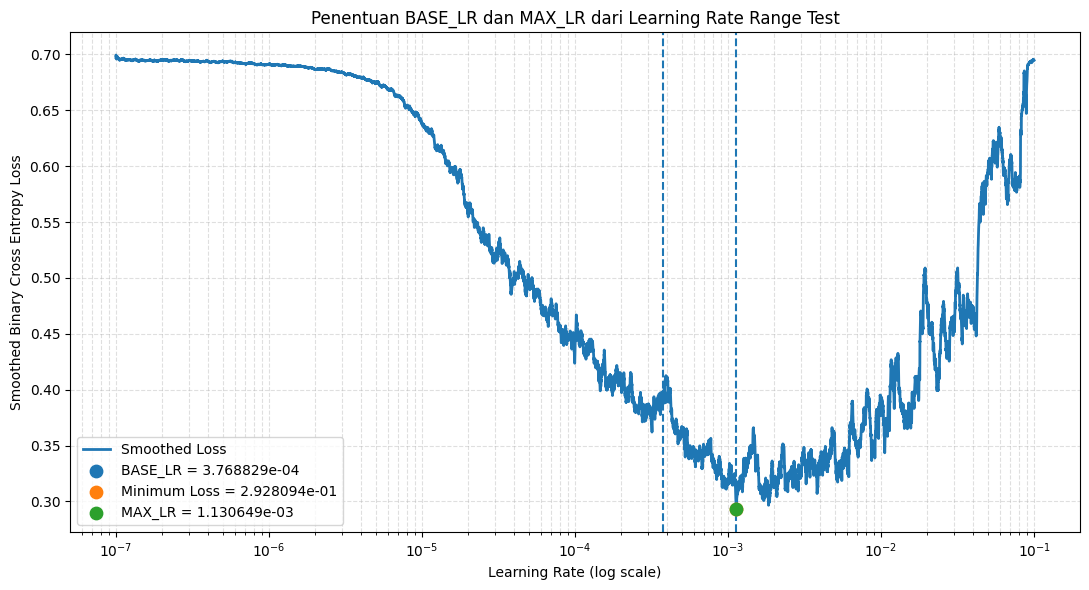

In [16]:
# Menentukan indeks learning rate terdekat dengan BASE_LR.
base_lr_index = int(
    np.argmin(
        np.abs(
            np.log10(analysis_lr)
            - np.log10(BASE_LR)
        )
    )
)

# Menentukan indeks learning rate terdekat dengan MAX_LR.
max_lr_index = int(
    np.argmin(
        np.abs(
            np.log10(analysis_lr)
            - np.log10(MAX_LR)
        )
    )
)

# Membuat grafik LRRT untuk menunjukkan boundary.
plt.figure(figsize=(11, 6))

# Menggambar kurva smoothed loss.
plt.plot(
    analysis_lr,
    analysis_loss,
    linewidth=2,
    label="Smoothed Loss"
)

# Menandai BASE_LR.
plt.scatter(
    analysis_lr[base_lr_index],
    analysis_loss[base_lr_index],
    s=80,
    zorder=5,
    label=f"BASE_LR = {BASE_LR:.6e}"
)

# Menandai minimum loss.
plt.scatter(
    analysis_lr[minimum_loss_index],
    analysis_loss[minimum_loss_index],
    s=80,
    zorder=5,
    label=f"Minimum Loss = {MINIMUM_LOSS:.6e}"
)

# Menandai MAX_LR.
plt.scatter(
    analysis_lr[max_lr_index],
    analysis_loss[max_lr_index],
    s=80,
    zorder=5,
    label=f"MAX_LR = {MAX_LR:.6e}"
)

# Menambahkan garis vertikal pada BASE_LR.
plt.axvline(
    BASE_LR,
    linestyle="--",
    linewidth=1.5
)

# Menambahkan garis vertikal pada MAX_LR.
plt.axvline(
    MAX_LR,
    linestyle="--",
    linewidth=1.5
)

# Menggunakan skala logaritmik pada learning rate.
plt.xscale("log")

# Memberikan label sumbu learning rate.
plt.xlabel(
    "Learning Rate (log scale)"
)

# Memberikan label sumbu loss.
plt.ylabel(
    "Smoothed Binary Cross Entropy Loss"
)

# Memberikan judul grafik.
plt.title(
    "Penentuan BASE_LR dan MAX_LR dari Learning Rate Range Test"
)

# Menampilkan legenda.
plt.legend()

# Menampilkan grid.
plt.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Eksperimen 1 - *Fixed Learning Rate*

Model CNN dilatih menggunakan *learning rate* tetap selama proses pelatihan

Konfigurasi:
- Optimizer: Adam
- Loss: *Binary Cross Entropy*
- Learning Rate: 0.001 atau 1e-3
- Epoch Maksimum: 50
- Dataset: CIFAKE
- Arsitektur: CNN yang telah ditetapkan

Model terbaik dipilih berdasarkan nilai validation loss terendah.


In [17]:
# Membuat model dan checkpoint untuk skenario Fixed Leaerning Rate
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_fixed = build_model(seed=SEED)

model_fixed.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FIXED_LR),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

fixed_checkpoint_path = (CHECKPOINT_DIR / "fixed_best.weights.h5")

checkpoint_fixed = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(fixed_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

history_fixed = model_fixed.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_fixed],
    verbose=1
)

model_fixed.load_weights(fixed_checkpoint_path)

best_epoch_fixed = (np.argmin(history_fixed.history["val_loss"]) + 1)

fixed_best_epoch = best_epoch_fixed

best_val_loss_fixed = (
    history_fixed.history["val_loss"][best_epoch_fixed - 1]
)

best_val_accuracy_fixed = (history_fixed.history["val_accuracy"][best_epoch_fixed - 1])

print("\nHASIL PELATIHAN FIXED LEARNING RATE\n")
print(f"Learning rate       : {FIXED_LR:.2e}")
print(f"Epoch pelatihan     : {EPOCHS}")
print(f"Epoch terbaik       : {best_epoch_fixed}")
print(f"Best validation loss: {best_val_loss_fixed:.6f}")
print(f"Validation accuracy : {best_val_accuracy_fixed:.6f}")

Epoch 1/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.8457 - loss: 0.3475 - val_accuracy: 0.8882 - val_loss: 0.2680
Epoch 2/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 40s 8ms/step - accuracy: 0.9054 - loss: 0.2328 - val_accuracy: 0.9131 - val_loss: 0.2083
Epoch 3/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9210 - loss: 0.1974 - val_accuracy: 0.9212 - val_loss: 0.1905
Epoch 4/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9303 - loss: 0.1763 - val_accuracy: 0.9323 - val_loss: 0.1710
Epoch 5/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 41s 8ms/step - accuracy: 0.9350 - loss: 0.1627 - val_accuracy: 0.9252 - val_loss: 0.1863
Epoch 6/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.9406 - loss: 0.1523 - val_accuracy: 0.9278 - val_loss: 0.1820
Epoch 7/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.9450 - loss: 0.1389 - val_accuracy: 0.9334 - val_loss: 0.1648
Epoch 8/50
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.9503 - loss: 0

## Visualisasi Loss *Fixed Learning Rate*

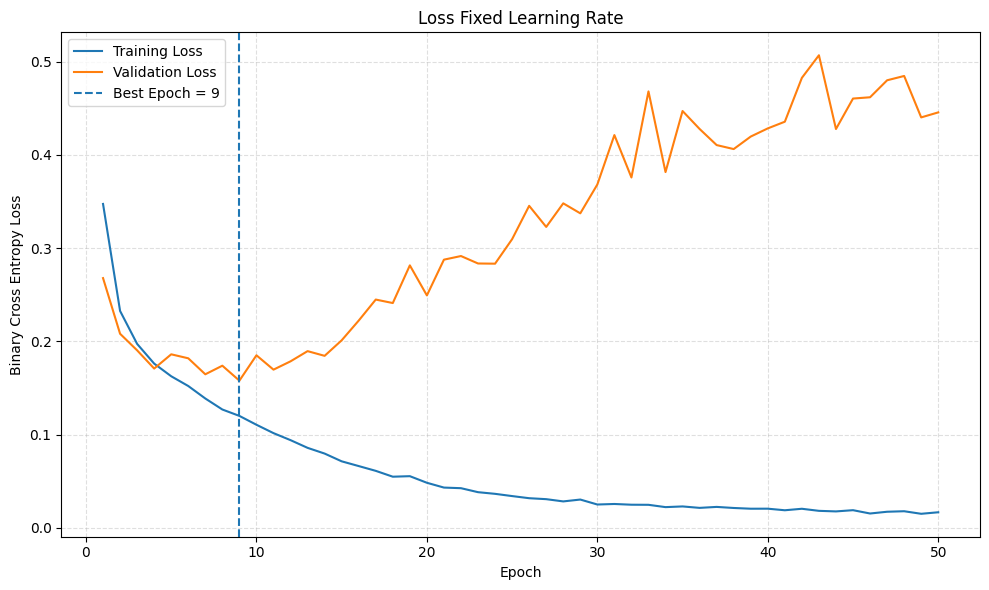

In [18]:
# Menampilkan kurva loss pelatihan Fixed Learning Rate
epochs_range = range(
    1,
    len(history_fixed.history["loss"]) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_fixed.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_fixed.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Loss Fixed Learning Rate")
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

## Visualisasi Accuracy Fixed Learning Rate

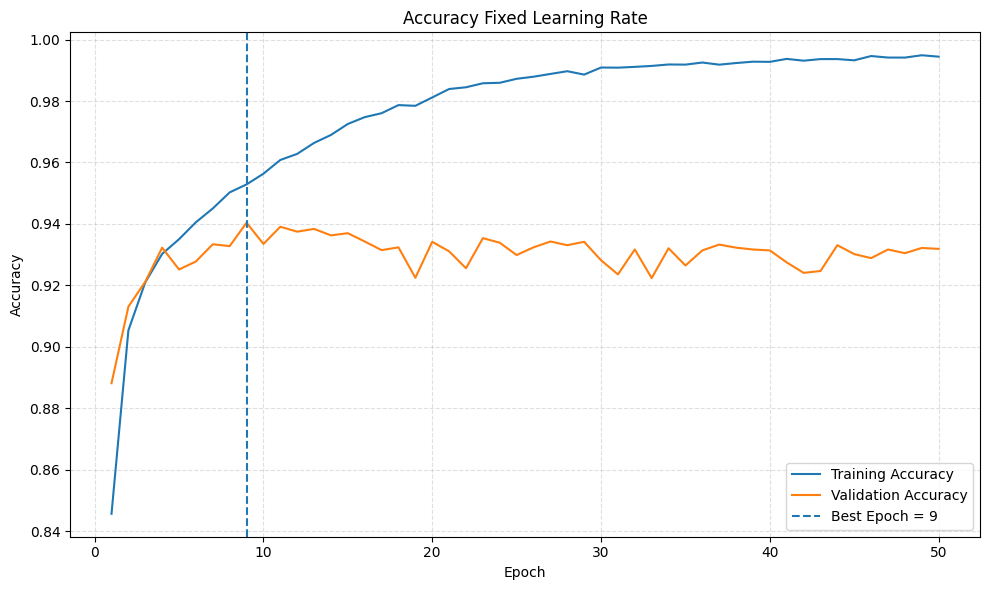

In [19]:
# Menampilkan kurva accuracy pelatihan Fixed Learning Rate
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_fixed.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_fixed.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch_fixed,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_fixed}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Fixed Learning Rate")
plt.legend()
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

## Evaluasi Fixed Learning Rate pada Data Testing

In [20]:
# Mengevaluasi model terbaik pada data pengujian
test_results_fixed = model_fixed.evaluate(
    test_ds,
    verbose=0,
    return_dict=True
)

y_true_fixed = []
y_probability_fixed = []

for batch_images, batch_labels in test_ds:

    batch_probability = model_fixed.predict(
        batch_images,
        verbose=0
    ).reshape(-1)

    y_true_fixed.extend(
        batch_labels.numpy().astype(int)
    )

    y_probability_fixed.extend(
        batch_probability
    )

y_true_fixed = np.array(
    y_true_fixed
)

y_probability_fixed = np.array(
    y_probability_fixed
)

y_pred_fixed = (
    y_probability_fixed >= 0.5
).astype(int)

fixed_accuracy = accuracy_score(
    y_true_fixed,
    y_pred_fixed
)

fixed_precision = precision_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_recall = recall_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_f1 = f1_score(
    y_true_fixed,
    y_pred_fixed,
    zero_division=0
)

fixed_test_loss = test_results_fixed["loss"]

print("HASIL EVALUASI FIXED LEARNING RATE\n")

print(f"Test Loss     : {fixed_test_loss:.6f}")
print(f"Test Accuracy : {fixed_accuracy:.6f}")
print(f"Test Precision: {fixed_precision:.6f}")
print(f"Test Recall   : {fixed_recall:.6f}")
print(f"Test F1-Score : {fixed_f1:.6f}")

HASIL EVALUASI FIXED LEARNING RATE

Test Loss     : 0.164628
Test Accuracy : 0.938850
Test Precision: 0.938894
Test Recall   : 0.938800
Test F1-Score : 0.938847


## Classification Report dan Confusion Matrix Fixed Learning Rate

CLASSIFICATION REPORT

              precision    recall  f1-score   support

        REAL     0.9388    0.9389    0.9389     10000
        FAKE     0.9389    0.9388    0.9388     10000

    accuracy                         0.9388     20000
   macro avg     0.9389    0.9388    0.9388     20000
weighted avg     0.9389    0.9388    0.9388     20000

CONFUSION MATRIX

[[9389  611]
 [ 612 9388]]


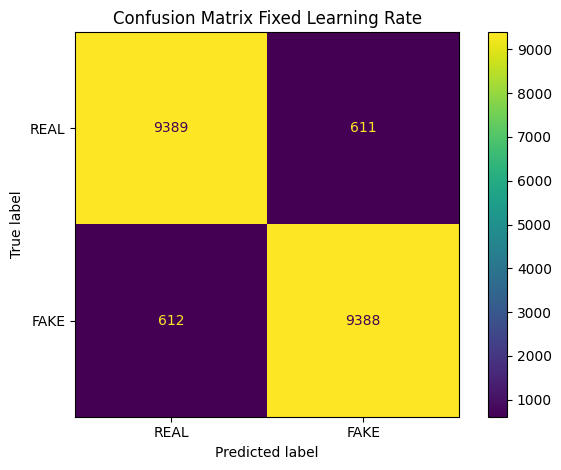

In [21]:
# Menampilkan classification report dan confusion matrix
print("CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true_fixed,
        y_pred_fixed,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

confusion_fixed = confusion_matrix(
    y_true_fixed,
    y_pred_fixed
)

print("CONFUSION MATRIX\n")
print(confusion_fixed)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_fixed,
    display_labels=CLASS_NAMES
).plot()

plt.title(
    "Confusion Matrix Fixed Learning Rate"
)

plt.tight_layout()
plt.show()

## Menyimpan hasil Fixed Learning Rate

In [22]:
# Mengambil seluruh riwayat pelatihan Fixed Learning Rate
fixed_history = pd.DataFrame(
    history_fixed.history
)

# Menambahkan nomor epoch
fixed_history.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(fixed_history) + 1
    )
)

# Menambahkan nama strategi
fixed_history.insert(
    0,
    "Strategy",
    "Fixed Learning Rate"
)

# Menandai epoch dengan validation loss terbaik
fixed_history["Best Epoch"] = (
    fixed_history["val_loss"]
    == fixed_history["val_loss"].min()
)

# Menampilkan seluruh riwayat pelatihan
display(
    fixed_history
)

# Menyimpan seluruh riwayat setiap epoch
fixed_history.to_csv(
    RESULTS_DIR / "fixed_training_history.csv",
    index=False
)

# Menyimpan hasil evaluasi akhir pada data testing
fixed_results = pd.DataFrame([
    {
        "Strategy": "Fixed Learning Rate",
        "Best Epoch": best_epoch_fixed,
        "Test Loss": fixed_test_loss,
        "Test Accuracy": fixed_accuracy,
        "Test Precision": fixed_precision,
        "Test Recall": fixed_recall,
        "Test F1-Score": fixed_f1
    }
])

# Menampilkan hasil evaluasi akhir
display(
    fixed_results
)

# Menyimpan hasil evaluasi akhir
fixed_results.to_csv(
    RESULTS_DIR / "fixed_test_results.csv",
    index=False
)

,Strategy,Epoch,accuracy,loss,val_accuracy,val_loss,Best Epoch
0,Fixed Learning Rate,1,0.845733,0.347519,0.8882,0.267985,False
1,Fixed Learning Rate,2,0.905400,0.232757,0.9131,0.208277,False
2,Fixed Learning Rate,3,0.921022,0.197425,0.9212,0.190507,False
3,Fixed Learning Rate,4,0.930267,0.176280,0.9323,0.170974,False
4,Fixed Learning Rate,5,0.935044,0.162710,0.9252,0.186257,False
5,Fixed Learning Rate,6,0.940567,0.152252,0.9278,0.181971,False
6,Fixed Learning Rate,7,0.945044,0.138869,0.9334,0.164827,False
7,Fixed Learning Rate,8,0.950278,0.127058,0.9328,0.174043,False
8,Fixed Learning Rate,9,0.952867,0.120195,0.9404,0.158009,True
9,Fixed Learning Rate,10,0.956356,0.110706,0.9335,0.185203,False


,Strategy,Best Epoch,Test Loss,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Fixed Learning Rate,9,0.164628,0.93885,0.938894,0.9388,0.938847


# Eksperimen 2 - *Cyclical Learning Rate (CLR) Triangular2*

Model CNN dilatih menggunakan **Cyclical Learning Rate mode Triangular2**

Learning rate bergerak secara suklik antara `BASE_LR` dan `MAX_LR`, sedangkan amplitudo siklus berikutnya dikurangi menjadi setengah dari siklus sebelumnya.

Eksperimen menggunakan arsitektur CNN, optimizer, fungsi loss, dataset, batch size, dan jumlah epoch yang sama dengan skenario **Fixed Learning Rate**.
Perbedaan utama terletak pada strategi learning rate

## Implementasi Schedule Triangular2

In [23]:
# Membuat learning rate schedule Triangular2.
class Triangular2LearningRate(
    tf.keras.optimizers.schedules.LearningRateSchedule
):

    # Membuat initializer schedule.
    def __init__(
        self,
        base_lr,
        max_lr,
        step_size
    ):

        # Menginisialisasi parent class.
        super().__init__()

        # Menyimpan BASE_LR.
        self.base_lr = float(base_lr)

        # Menyimpan MAX_LR.
        self.max_lr = float(max_lr)

        # Menyimpan STEP_SIZE.
        self.step_size = float(step_size)

    # Menghitung learning rate berdasarkan training step.
    def __call__(self, step):

        # Mengubah step menjadi float TensorFlow.
        step = tf.cast(
            step,
            tf.float32
        )

        # Menghitung nomor cycle.
        cycle = tf.floor(
            1.0
            + step
            / (2.0 * self.step_size)
        )

        # Menghitung posisi relatif dalam cycle.
        x = tf.abs(
            step / self.step_size
            - 2.0 * cycle
            + 1.0
        )

        # Menghitung triangular scale.
        scale = tf.maximum(
            0.0,
            1.0 - x
        )

        # Menghitung amplitude awal.
        amplitude = (
            self.max_lr
            - self.base_lr
        )

        # Membagi amplitude menjadi setengah setiap cycle.
        scaled_amplitude = (
            amplitude
            / tf.pow(
                2.0,
                cycle - 1.0
            )
        )

        # Menghitung learning rate akhir.
        lr = (
            self.base_lr
            + scaled_amplitude * scale
        )

        # Mengembalikan learning rate.
        return lr

    # Mengembalikan konfigurasi schedule.
    def get_config(self):

        # Menyimpan parameter schedule.
        return {
            "base_lr": self.base_lr,
            "max_lr": self.max_lr,
            "step_size": self.step_size
        }


# Menampilkan status class.
print(
    "Class Triangular2LearningRate berhasil dibuat."
)

Class Triangular2LearningRate berhasil dibuat.


## Konfigurasi CLR

In [24]:
# Memastikan BASE_LR telah ditentukan.
if BASE_LR is None:

    # Menghentikan eksperimen jika BASE_LR belum tersedia.
    raise ValueError(
        "BASE_LR belum ditentukan."
    )

# Memastikan MAX_LR telah ditentukan.
if MAX_LR is None:

    # Menghentikan eksperimen jika MAX_LR belum tersedia.
    raise ValueError(
        "MAX_LR belum ditentukan."
    )

# Menghitung jumlah step training per epoch.
STEPS_PER_EPOCH = math.ceil(
    len(train_paths) / BATCH_SIZE
)

# Menentukan multiplier STEP_SIZE.
STEP_SIZE_MULTIPLIER = 5

# Menghitung STEP_SIZE sebagai lima kali step per epoch.
STEP_SIZE = (
    STEP_SIZE_MULTIPLIER
    * STEPS_PER_EPOCH
)

# Menghitung panjang satu cycle penuh.
FULL_CYCLE_STEPS = (
    2 * STEP_SIZE
)

# Menghitung total step training.
TOTAL_TRAINING_STEPS = (
    EPOCHS
    * STEPS_PER_EPOCH
)

# Menghitung jumlah cycle selama training.
NUMBER_OF_CYCLES = (
    TOTAL_TRAINING_STEPS
    / FULL_CYCLE_STEPS
)

# Membuat schedule Triangular2.
clr_schedule = Triangular2LearningRate(
    base_lr=BASE_LR,
    max_lr=MAX_LR,
    step_size=STEP_SIZE
)

# Menampilkan konfigurasi CLR.
print("KONFIGURASI CLR\n")
print(
    f"base_lr       : {BASE_LR:.6e}"
)
print(
    f"max_lr        : {MAX_LR:.6e}"
)
print(
    f"steps/epoch   : {STEPS_PER_EPOCH:,}"
)
print(
    f"step multiplier: {STEP_SIZE_MULTIPLIER}"
)
print(
    f"step_size     : {STEP_SIZE:,}"
)
print(
    f"total steps   : {TOTAL_TRAINING_STEPS:,}"
)
print(
    f"cycle penuh   : {FULL_CYCLE_STEPS:,} steps"
)
print(
    f"jumlah cycle  : {NUMBER_OF_CYCLES:.2f}"
)

KONFIGURASI CLR

base_lr       : 3.768829e-04
max_lr        : 1.130649e-03
steps/epoch   : 2,813
step multiplier: 5
step_size     : 14,065
total steps   : 140,650
cycle penuh   : 28,130 steps
jumlah cycle  : 5.00


## Verifikasi Schedule Triangular2
Visualisasi ini digunakan untuk memastikan bahwa schedule menghasilkan pola learning rate sesuai karakteristik Triangular2 sebelum digunakan dalam proses pelatihan model.

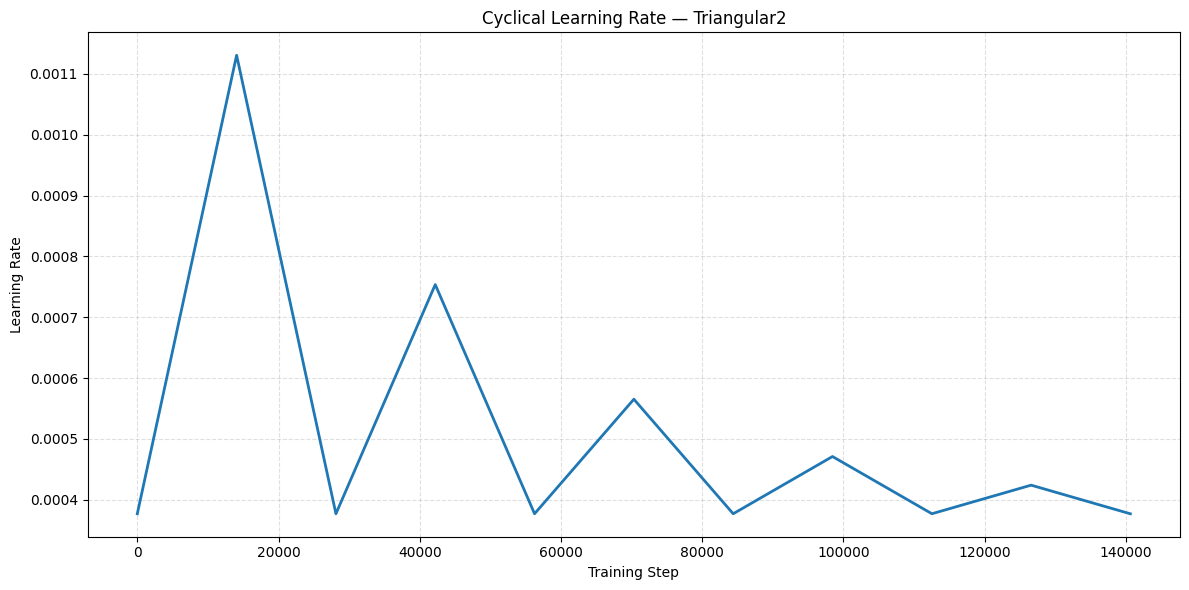

VERIFIKASI CLR

LR minimum : 3.768829e-04
LR maksimum: 1.130595e-03


In [25]:
# Menentukan jumlah titik untuk visualisasi.
plot_count = min(
    TOTAL_TRAINING_STEPS + 1,
    10000
)

# Membuat array training step dari awal hingga akhir training.
steps_for_plot = np.linspace(
    0,
    TOTAL_TRAINING_STEPS,
    plot_count,
    dtype=np.int64
)

# Menghitung learning rate pada setiap training step.
lr_curve = clr_schedule(
    tf.constant(
        steps_for_plot,
        dtype=tf.float32
    )
).numpy()

# Membuat figure schedule CLR.
plt.figure(figsize=(12, 6))

# Menggambar kurva learning rate.
plt.plot(
    steps_for_plot,
    lr_curve,
    linewidth=2
)

# Memberikan label sumbu training step.
plt.xlabel(
    "Training Step"
)

# Memberikan label sumbu learning rate.
plt.ylabel(
    "Learning Rate"
)

# Memberikan judul grafik.
plt.title(
    "Cyclical Learning Rate — Triangular2"
)

# Menampilkan grid.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Menampilkan nilai minimum dan maksimum schedule.
print("VERIFIKASI CLR\n")
print(
    f"LR minimum : {lr_curve.min():.6e}"
)
print(
    f"LR maksimum: {lr_curve.max():.6e}"
)

## Pencatatan Learning Rate selama Pelatihan

In [26]:
class LearningRateHistory(tf.keras.callbacks.Callback):

  # Membuat konstruktor callback dengan menerima schedule CLR
  def __init__(self, schedule):
    super().__init__()

    # Menyimpan schedule yang digunakan dalam training
    self.schedule = schedule

    # Menyiapkan list untuk menyimpan training step
    self.steps = []

    # Menyiapkan list untuk menyimpan learning step
    self.learning_rates = []

  # Mengatur ulang pencatatan saat training dimulai
  def on_train_begin(self, logs=None):
    self.steps = []
    self.learning_rates = []

  # Mencatat learning rate sebelum setiap batch training dijalankan
  def on_train_batch_begin(self, batch, logs=None):

    # Mengambil training step saat ini dari optimizer
    step = int(self.model.optimizer.iterations.numpy())

    # Menghitung learning rate schedule pada training step tersebut
    learning_rate = float(
        self.schedule(
        tf.constant(step, dtype=tf.float32)
      ).numpy()
    )

    # Menyimpan training step yang sedang digunakan
    self.steps.append(step)

    # Menyimpan learning rate pada training step tersebut
    self.learning_rates.append(learning_rate)

print("Callback Learning Rate History berhasil dibuat")

Callback Learning Rate History berhasil dibuat


## Persiapan Model dan dataset CLR

In [27]:
# Membersihkan session tensorflow dari model atau graph sebelumnya
tf.keras.backend.clear_session()

# Membersihkan objek python yang sudah tidak digunakan dari memory
gc.collect()

# Menetapkan seed untuk reproduktifitas
tf.keras.utils.set_random_seed(SEED)

# Memastikan folder checkpoint tersedia
CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Menentukan lokasi file checkpoint model CLR terbaik
clr_checkpoint_path = (CHECKPOINT_DIR / "clr_best.weights.h5")

# Pemeriksaan checkpoint lama
if clr_checkpoint_path.exists():
    clr_checkpoint_path.unlink()

# Membuat model CNN baru menggunakan arsitektur yang sama
model_clr = build_model(seed=SEED)

model_clr.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=clr_schedule
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)

# Membuat dataset training khusus eksperimen CLR
train_ds_clr = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)

# Membuat callback untuk mencatat learning rate pada setiap training step
lr_history_callback = LearningRateHistory(
    clr_schedule
)

# Membuat callback untuk menyimpan model dengan validation loss terbaik
checkpoint_clr = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clr_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)

print("Persiapan Model dan Dataset CLR Selesai")

Persiapan Model dan Dataset CLR Selesai


## Pelatihan Model dengan CLR Triangular2

In [28]:
# Membersihkan session TensorFlow sebelumnya.
tf.keras.backend.clear_session()

# Membersihkan objek yang tidak digunakan.
gc.collect()

# Mengatur ulang random seed.
tf.keras.utils.set_random_seed(SEED)

# Menentukan lokasi checkpoint CLR.
clr_checkpoint = (
    CHECKPOINT_DIR
    / "clr_best.weights.h5"
)

# Menghapus checkpoint lama jika tersedia.
if clr_checkpoint.exists():
    clr_checkpoint.unlink()


# Membuat model CLR baru.
model_clr = build_model(
    seed=SEED
)

# Mengompilasi model menggunakan Adam dengan CLR schedule.
model_clr.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=clr_schedule
    ),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)


# Membuat dataset training CLR.
train_ds_clr = make_dataset(
    train_paths,
    train_labels,
    shuffle=True,
    seed=SEED,
    cache=False
)


# Membuat checkpoint berdasarkan validation loss.
checkpoint_clr = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(clr_checkpoint),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=0
)


# Membuat callback untuk mencatat actual learning rate.
class LearningRateHistory(
    tf.keras.callbacks.Callback
):

    # Membuat initializer callback.
    def __init__(
        self,
        schedule
    ):

        # Menginisialisasi parent callback.
        super().__init__()

        # Menyimpan CLR schedule.
        self.schedule = schedule

        # Membuat list training step.
        self.steps = []

        # Membuat list learning rate.
        self.learning_rates = []

    # Mengosongkan history saat training dimulai.
    def on_train_begin(
        self,
        logs=None
    ):

        # Mengosongkan training step.
        self.steps = []

        # Mengosongkan learning rate.
        self.learning_rates = []

    # Mencatat actual learning rate sebelum setiap batch.
    def on_train_batch_begin(
        self,
        batch,
        logs=None
    ):

        # Mengambil optimizer iteration saat ini.
        step = int(
            self.model.optimizer.iterations.numpy()
        )

        # Menghitung learning rate dari schedule.
        learning_rate = float(
            self.schedule(
                tf.constant(
                    step,
                    dtype=tf.float32
                )
            ).numpy()
        )

        # Menyimpan training step.
        self.steps.append(
            step
        )

        # Menyimpan actual learning rate.
        self.learning_rates.append(
            learning_rate
        )


# Membuat callback actual learning rate.
lr_history_callback = LearningRateHistory(
    clr_schedule
)


# Menampilkan konfigurasi training.
print("TRAINING CLR TRIANGULAR2\n")
print(
    f"base_lr : {BASE_LR:.6e}"
)
print(
    f"max_lr  : {MAX_LR:.6e}"
)
print(
    f"step_size: {STEP_SIZE:,}"
)
print(
    f"epochs  : {EPOCHS}"
)
print(
    f"cycles  : {NUMBER_OF_CYCLES:.2f}"
)


# Menjalankan training CLR.
history_clr = model_clr.fit(
    train_ds_clr,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint_clr,
        lr_history_callback
    ],
    verbose=2
)


# Memuat bobot model dengan validation loss terbaik.
model_clr.load_weights(
    clr_checkpoint
)


# Membuat DataFrame dari training history.
history_clr_df = pd.DataFrame(
    history_clr.history
)

# Mengubah index history menjadi nomor epoch.
history_clr_df.index = (
    history_clr_df.index + 1
)

# Memberikan nama pada index history.
history_clr_df.index.name = "epoch"

# Menyimpan history CLR.
history_clr_df.to_csv(
    RESULTS_DIR
    / "history_clr.csv"
)


# Mengubah training step menjadi NumPy array.
lr_history_steps = np.asarray(
    lr_history_callback.steps,
    dtype=np.int64
)

# Mengubah actual learning rate menjadi NumPy array.
lr_history_values = np.asarray(
    lr_history_callback.learning_rates,
    dtype=np.float64
)

# Menentukan epoch dari setiap training step.
lr_history_epochs = (
    lr_history_steps
    // STEPS_PER_EPOCH
) + 1

# Membuat DataFrame actual learning rate.
clr_lr_history = pd.DataFrame({
    "Epoch": lr_history_epochs,
    "Training Step": lr_history_steps,
    "Learning Rate": lr_history_values
})

# Menghitung statistik learning rate setiap epoch.
clr_lr_epoch_summary = (
    clr_lr_history
    .groupby("Epoch")["Learning Rate"]
    .agg(
        Learning_Rate_Min="min",
        Learning_Rate_Max="max",
        Learning_Rate_Mean="mean"
    )
    .reset_index()
)

# Menampilkan status training selesai.
print(
    "\nModel CLR terbaik berhasil dimuat."
)

TRAINING CLR TRIANGULAR2

base_lr : 3.768829e-04
max_lr  : 1.130649e-03
step_size: 14,065
epochs  : 50
cycles  : 5.00
Epoch 1/50
2813/2813 - 29s - 10ms/step - accuracy: 0.8293 - loss: 0.3788 - val_accuracy: 0.8805 - val_loss: 0.3004
Epoch 2/50
2813/2813 - 28s - 10ms/step - accuracy: 0.8921 - loss: 0.2630 - val_accuracy: 0.9113 - val_loss: 0.2256
Epoch 3/50
2813/2813 - 28s - 10ms/step - accuracy: 0.9106 - loss: 0.2213 - val_accuracy: 0.9035 - val_loss: 0.2352
Epoch 4/50
2813/2813 - 29s - 10ms/step - accuracy: 0.9211 - loss: 0.1979 - val_accuracy: 0.9217 - val_loss: 0.1954
Epoch 5/50
2813/2813 - 28s - 10ms/step - accuracy: 0.9277 - loss: 0.1825 - val_accuracy: 0.9329 - val_loss: 0.1747
Epoch 6/50
2813/2813 - 28s - 10ms/step - accuracy: 0.9334 - loss: 0.1686 - val_accuracy: 0.9339 - val_loss: 0.1723
Epoch 7/50
2813/2813 - 28s - 10ms/step - accuracy: 0.9409 - loss: 0.1489 - val_accuracy: 0.9331 - val_loss: 0.1691
Epoch 8/50
2813/2813 - 29s - 10ms/step - accuracy: 0.9494 - loss: 0.1293 - va

## Verifikasi Learning Rate Aktual dan Riwayat Pelatihan

Data learning rate yang dicatat selama training diolah menjadi data per-step dan ringkasan per-epoch. Data tersebut kemudian digabungkan dengan riwayat loss dan accuracy hasil pelatihan.

In [29]:
# Mengubah daftar training step menjadi numpy array.
lr_steps = np.asarray(
    lr_history_callback.steps,
    dtype=np.int64
)

# Mengubah daftar learning rate menjadi numpy array.
lr_values = np.asarray(
    lr_history_callback.learning_rates,
    dtype=np.float64
)

# Mengubah training step menjadi nomor epoch.
lr_epochs = (
    lr_steps // STEPS_PER_EPOCH
) + 1

# Membuat dataframe berisi learning rate pada setiap training step.
clr_lr_history = pd.DataFrame({
    "Epoch": lr_epochs,
    "Training Step": lr_steps,
    "Learning Rate": lr_values
})

# Mengelompokkan learning rate berdasarkan epoch.
epoch_lr_summary = (
    clr_lr_history
    .groupby("Epoch")["Learning Rate"]
    .agg(
        Learning_Rate_Min="min",
        Learning_Rate_Max="max",
        Learning_Rate_Mean="mean"
    )
    .reset_index()
)

# Mengubah history TensorFlow menjadi dataframe.
clr_history_df = pd.DataFrame(
    history_clr.history
)

# Menambahkan nomor epoch sebagai kolom pertama.
clr_history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(clr_history_df) + 1
    )
)

# Menggabungkan history training dengan ringkasan learning rate per epoch.
clr_history_df = clr_history_df.merge(
    epoch_lr_summary,
    on="Epoch",
    how="left"
)

# Menentukan epoch dengan validation loss terendah.
clr_best_epoch = (
    np.argmin(
        clr_history_df["val_loss"].to_numpy()
    ) + 1
)

# Menandai baris yang merupakan epoch terbaik.
clr_history_df["Best Epoch"] = (
    clr_history_df["Epoch"]
    == clr_best_epoch
)

# Menampilkan riwayat lengkap training CLR.
display(clr_history_df)

# Menampilkan jumlah training step yang berhasil dicatat.
print(
    f"\nJumlah training step yang tercatat : "
    f"{len(clr_lr_history):,}"
)

# Menampilkan learning rate minimum yang tercatat.
print(
    f"Learning rate minimum aktual        : "
    f"{lr_values.min():.6e}"
)

# Menampilkan learning rate maksimum yang tercatat.
print(
    f"Learning rate maksimum aktual       : "
    f"{lr_values.max():.6e}"
)

,Epoch,accuracy,loss,val_accuracy,val_loss,Learning_Rate_Min,Learning_Rate_Max,Learning_Rate_Mean,Best Epoch
0,1,0.829311,0.378828,0.8805,0.300350,0.000377,0.000528,0.000452,False
1,2,0.892056,0.262995,0.9113,0.225559,0.000528,0.000678,0.000603,False
2,3,0.910556,0.221323,0.9035,0.235171,0.000678,0.000829,0.000754,False
3,4,0.921133,0.197878,0.9217,0.195367,0.000829,0.000980,0.000904,False
4,5,0.927667,0.182538,0.9329,0.174695,0.000980,0.001131,0.001055,False
5,6,0.933444,0.168621,0.9339,0.172335,0.000980,0.001131,0.001055,False
6,7,0.940889,0.148928,0.9331,0.169145,0.000829,0.000980,0.000905,False
7,8,0.949389,0.129318,0.9367,0.158909,0.000678,0.000829,0.000754,False
8,9,0.956933,0.110704,0.9374,0.165175,0.000528,0.000678,0.000603,False
9,10,0.963056,0.095878,0.9420,0.160672,0.000377,0.000528,0.000452,False



Jumlah training step yang tercatat : 140,650
Learning rate minimum aktual        : 3.768829e-04
Learning rate maksimum aktual       : 1.130649e-03


## Visualisasi Learning Rate Aktual Selama Pelatihan

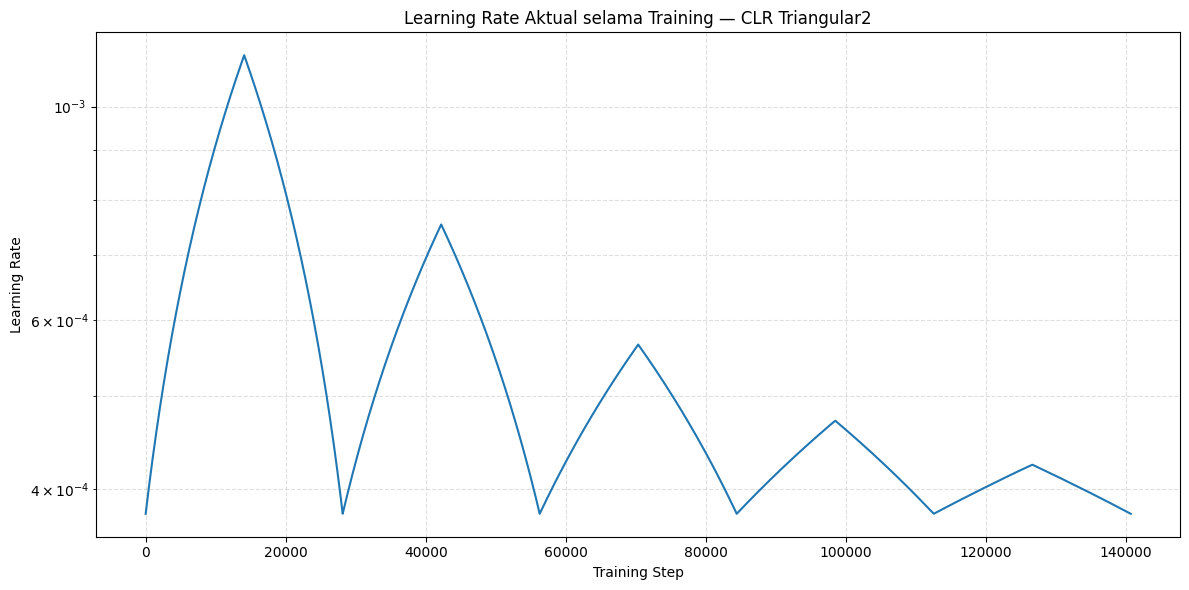

In [30]:
# Membuat area gambar untuk learning rate aktual.
plt.figure(figsize=(12, 6))

# Menggambar learning rate aktual terhadap training step.
plt.plot(
    clr_lr_history["Training Step"],
    clr_lr_history["Learning Rate"],
    linewidth=1.5
)

# Memberikan label pada sumbu horizontal.
plt.xlabel("Training Step")

# Memberikan label pada sumbu vertikal.
plt.ylabel("Learning Rate")

# Memberikan judul grafik learning rate aktual.
plt.title(
    "Learning Rate Aktual selama Training — CLR Triangular2"
)

# Menggunakan skala logaritmik pada sumbu learning rate.
plt.yscale("log")

# Menampilkan grid utama dan grid minor.
plt.grid(
    True,
    linestyle="--",
    which="both",
    alpha=0.4
)

# Menyesuaikan tata letak elemen grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Loss dan Learning Rate Aktual

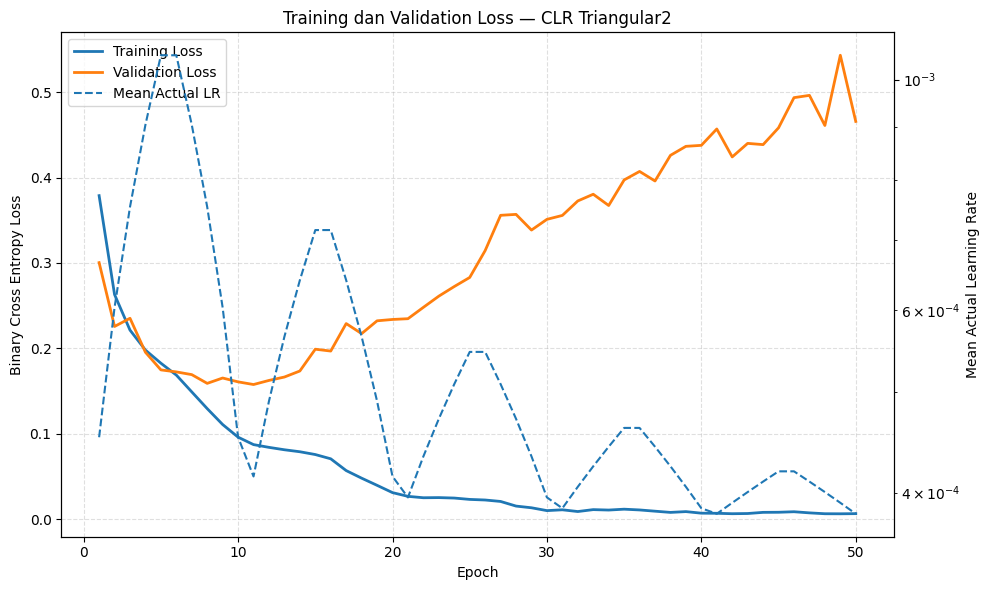

In [31]:
# Membuat array epoch untuk grafik.
epochs_axis_clr = np.arange(
    1,
    len(
        history_clr.history["loss"]
    ) + 1
)

# Mengambil data validation dan training loss.
clr_plot_df = (
    history_clr_df
    .reset_index()
    .merge(
        clr_lr_epoch_summary,
        left_on="epoch",
        right_on="Epoch",
        how="left"
    )
)

# Membuat figure grafik loss.
fig, ax1 = plt.subplots(
    figsize=(10, 6)
)

# Menggambar training loss.
ax1.plot(
    epochs_axis_clr,
    history_clr.history["loss"],
    label="Training Loss",
    linewidth=2
)

# Menggambar validation loss.
ax1.plot(
    epochs_axis_clr,
    history_clr.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

# Memberikan label sumbu X.
ax1.set_xlabel(
    "Epoch"
)

# Memberikan label sumbu Y utama.
ax1.set_ylabel(
    "Binary Cross Entropy Loss"
)

# Membuat sumbu Y kedua untuk learning rate.
ax2 = ax1.twinx()

# Menggambar mean actual learning rate.
ax2.plot(
    clr_plot_df["epoch"],
    clr_plot_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.5,
    label="Mean Actual LR"
)

# Menggunakan skala logaritmik pada LR.
ax2.set_yscale(
    "log"
)

# Memberikan label sumbu Y kedua.
ax2.set_ylabel(
    "Mean Actual Learning Rate"
)

# Memberikan judul grafik.
ax1.set_title(
    "Training dan Validation Loss — CLR Triangular2"
)

# Mengambil legend dari kedua sumbu.
lines_1, labels_1 = (
    ax1.get_legend_handles_labels()
)

# Mengambil legend dari sumbu learning rate.
lines_2, labels_2 = (
    ax2.get_legend_handles_labels()
)

# Menggabungkan kedua legend.
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="best"
)

# Menampilkan grid.
ax1.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
fig.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Accuracy dan Learning Rate Aktual

Visualisasi ini digunakan untuk mengamati hubungan antara perubahan learning rate dengan training accuracy dan validation accuracy selama proses pelatihan model.

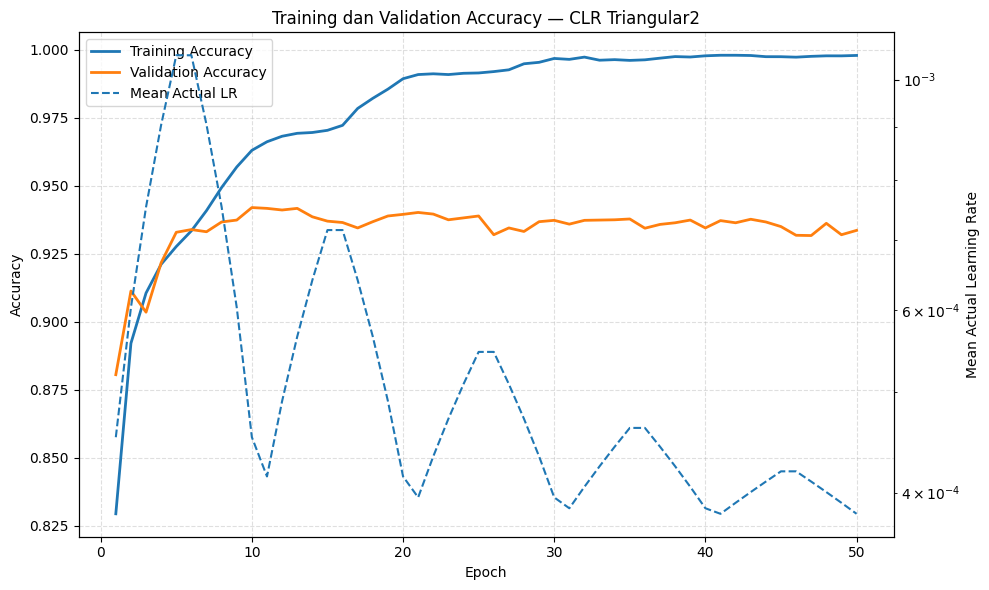

In [32]:
# Membuat figure grafik accuracy.
fig, ax1 = plt.subplots(
    figsize=(10, 6)
)

# Menggambar training accuracy.
ax1.plot(
    epochs_axis_clr,
    history_clr.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

# Menggambar validation accuracy.
ax1.plot(
    epochs_axis_clr,
    history_clr.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

# Memberikan label sumbu X.
ax1.set_xlabel(
    "Epoch"
)

# Memberikan label sumbu Y utama.
ax1.set_ylabel(
    "Accuracy"
)

# Membuat sumbu Y kedua untuk learning rate.
ax2 = ax1.twinx()

# Menggambar mean actual learning rate.
ax2.plot(
    clr_plot_df["epoch"],
    clr_plot_df["Learning_Rate_Mean"],
    linestyle="--",
    linewidth=1.5,
    label="Mean Actual LR"
)

# Menggunakan skala logaritmik pada LR.
ax2.set_yscale(
    "log"
)

# Memberikan label sumbu Y kedua.
ax2.set_ylabel(
    "Mean Actual Learning Rate"
)

# Memberikan judul grafik.
ax1.set_title(
    "Training dan Validation Accuracy — CLR Triangular2"
)

# Mengambil legend dari kedua sumbu.
lines_1, labels_1 = (
    ax1.get_legend_handles_labels()
)

# Mengambil legend learning rate.
lines_2, labels_2 = (
    ax2.get_legend_handles_labels()
)

# Menggabungkan legend.
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="best"
)

# Menampilkan grid.
ax1.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
fig.tight_layout()

# Menampilkan grafik.
plt.show()

## Penentuan Epoch Terbaik CLR

Epoch terbaik ditentukan berdasarkan nilai validation loss terendah. Validation accuracy maksimum juga dicatat sebagai informasi tambahan.

In [33]:
# Menentukan epoch terbaik berdasarkan validation loss dan accuracy.
clr_best_epoch, clr_best_acc_epoch = (
    get_best_epoch(
        history_clr
    )
)

# Menyimpan validation loss pada epoch terbaik.
clr_best_val_loss = (
    history_clr.history["val_loss"][
        clr_best_epoch - 1
    ]
)

# Menyimpan validation accuracy pada epoch terbaik.
clr_best_val_accuracy = (
    history_clr.history["val_accuracy"][
        clr_best_epoch - 1
    ]
)

# Menyimpan validation accuracy maksimum.
clr_best_acc_value = (
    history_clr.history["val_accuracy"][
        clr_best_acc_epoch - 1
    ]
)

# Menampilkan hasil epoch terbaik.
print(
    "EPOCH TERBAIK — CLR TRIANGULAR2\n"
)

print(
    f"Best epoch berdasarkan val_loss : "
    f"{clr_best_epoch}"
)

print(
    f"Best validation loss            : "
    f"{clr_best_val_loss:.6f}"
)

print(
    f"Validation accuracy pada epoch : "
    f"{clr_best_val_accuracy:.6f}"
)

print(
    f"Epoch validation accuracy max  : "
    f"{clr_best_acc_epoch}"
)

print(
    f"Maximum validation accuracy    : "
    f"{clr_best_acc_value:.6f}"
)

EPOCH TERBAIK — CLR TRIANGULAR2

Best epoch berdasarkan val_loss : 11
Best validation loss            : 0.157549
Validation accuracy pada epoch : 0.941700
Epoch validation accuracy max  : 10
Maximum validation accuracy    : 0.942000


## Evaluasi Model CLR pada Data Testing

Model terbaik yang telah dipilih berdasarkan validation loss dievaluasi menggunakan data testing yang tidak digunakan selama proses training.

## Evaluasi CLR

In [44]:
# Mengevaluasi model CLR terbaik pada data testing.
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)


# Menampilkan judul evaluasi CLR.
print(
    "HASIL TEST — CLR TRIANGULAR2"
)


# Menampilkan test loss.
print(
    f"Loss       : {clr_eval['Loss']:.6f}"
)

# Menampilkan test accuracy.
print(
    f"Accuracy   : {clr_eval['Accuracy']:.6f}"
)

# Menampilkan precision.
print(
    f"Precision  : {clr_eval['Precision']:.6f}"
)

# Menampilkan recall.
print(
    f"Recall     : {clr_eval['Recall']:.6f}"
)

# Menampilkan F1-score.
print(
    f"F1-score   : {clr_eval['F1-score']:.6f}"
)

# Menampilkan classification report.
print(
    "\nClassification Report:"
)

display(
    clr_eval[
        "classification_report"
    ]
)

HASIL TEST — CLR TRIANGULAR2
Loss       : 0.162139
Accuracy   : 0.942050
Precision  : 0.951763
Recall     : 0.931300
F1-score   : 0.941420

Classification Report:


,precision,recall,f1-score,support
REAL,0.932746,0.95280,0.942666,10000.00000
FAKE,0.951763,0.93130,0.941420,10000.00000
accuracy,0.942050,0.94205,0.942050,0.94205
macro avg,0.942254,0.94205,0.942043,20000.00000
weighted avg,0.942254,0.94205,0.942043,20000.00000


## Classification Report dan Confusion Matrix CLR

CONFUSION MATRIX — CLR
True Negative  (TN) : 9,528
False Positive (FP) : 472
False Negative (FN) : 687
True Positive  (TP) : 9,313


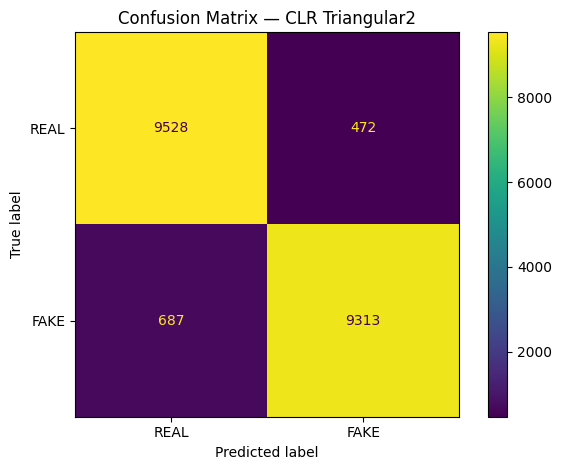

In [45]:
# Mengambil confusion matrix CLR.
clr_cm = clr_eval[
    "confusion_matrix"
]

# Mengambil TN, FP, FN, dan TP.
tn, fp, fn, tp = clr_cm.ravel()

# Menampilkan judul confusion matrix.
print(
    "CONFUSION MATRIX — CLR"
)

# Menampilkan True Negative.
print(
    f"True Negative  (TN) : {tn:,}"
)

# Menampilkan False Positive.
print(
    f"False Positive (FP) : {fp:,}"
)

# Menampilkan False Negative.
print(
    f"False Negative (FN) : {fn:,}"
)

# Menampilkan True Positive.
print(
    f"True Positive  (TP) : {tp:,}"
)

# Membuat tampilan confusion matrix.
disp = ConfusionMatrixDisplay(
    confusion_matrix=clr_cm,
    display_labels=CLASS_NAMES
)

# Menampilkan confusion matrix.
disp.plot(
    values_format="d"
)

# Memberikan judul confusion matrix.
plt.title(
    "Confusion Matrix — CLR Triangular2"
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Penyimpanan Hasil Eksperimen CLR

In [36]:
# Membuat DataFrame berisi metrik akhir model CLR.
clr_test_results = pd.DataFrame([
    {
        "Strategy": "CLR Triangular2",
        "Loss": clr_eval["Loss"],
        "Accuracy": clr_eval["Accuracy"],
        "Precision": clr_eval["Precision"],
        "Recall": clr_eval["Recall"],
        "F1-score": clr_eval["F1-score"],
        "Best Epoch": clr_best_epoch,
        "Best Validation Loss": clr_best_val_loss,
        "Best Validation Accuracy": clr_best_val_accuracy
    }
])

# Menyimpan metrik testing model CLR ke file CSV.
clr_test_results.to_csv(
    RESULTS_DIR / "clr_test_results.csv",
    index=False
)

# Menyimpan history training CLR per epoch ke file CSV.
clr_history_df.to_csv(
    RESULTS_DIR / "clr_training_history.csv",
    index=False
)

# Menyimpan learning rate pada setiap training step ke file CSV.
clr_lr_history.to_csv(
    RESULTS_DIR / "clr_learning_rate_history.csv",
    index=False
)

# Menampilkan lokasi penyimpanan seluruh hasil eksperimen.
print(
    f"Semua hasil CLR berhasil disimpan di: "
    f"{RESULTS_DIR}"
)

Semua hasil CLR berhasil disimpan di: /content/results


# Perbandingan Fixed Learning Rate dan CLR Triangular2

Bagian ini membandingkan hasil eksperimen Fixed Learning Rate dan Cyclical Learning Rate (CLR) mode Triangular2.

Perbandingan dilakukan pada dua aspek, yaitu dinamika proses pelatihan berdasarkan validation loss dan validation accuracy, serta performa akhir model berdasarkan data testing.

Kedua skenario menggunakan arsitektur CNN, dataset, batch size, jumlah epoch, optimizer, dan fungsi loss yang sama. Perbedaan utama terletak pada strategi learning rate.

## Persiapan Data Perbandingan

Sebelum hasil dibandingkan, epoch terbaik dari masing-masing eksperimen ditentukan berdasarkan validation loss terendah. Model pada kedua skenario juga dievaluasi kembali menggunakan dataset testing dengan fungsi evaluasi yang sama.

In [37]:
# Memastikan history Fixed Learning Rate tersedia sebelum perbandingan.
if "history_fixed" not in globals():
    # Menghentikan proses jika history Fixed Learning Rate belum tersedia.
    raise NameError(
        "history_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan history CLR tersedia sebelum perbandingan.
if "history_clr" not in globals():
    # Menghentikan proses jika history CLR belum tersedia.
    raise NameError(
        "history_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Memastikan model Fixed Learning Rate tersedia sebelum evaluasi.
if "model_fixed" not in globals():
    # Menghentikan proses jika model Fixed Learning Rate belum tersedia.
    raise NameError(
        "model_fixed belum tersedia. Jalankan training Fixed Learning Rate terlebih dahulu."
    )

# Memastikan model CLR tersedia sebelum evaluasi.
if "model_clr" not in globals():
    # Menghentikan proses jika model CLR belum tersedia.
    raise NameError(
        "model_clr belum tersedia. Jalankan training CLR terlebih dahulu."
    )

# Menentukan epoch dengan validation loss terendah pada Fixed Learning Rate.
fixed_best_epoch = (
    np.argmin(
        history_fixed.history["val_loss"]
    ) + 1
)

# Menentukan epoch dengan validation loss terendah pada CLR Triangular2.
clr_best_epoch = (
    np.argmin(
        history_clr.history["val_loss"]
    ) + 1
)

# Mengambil validation loss terbaik Fixed Learning Rate.
fixed_best_val_loss = (
    history_fixed.history["val_loss"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation loss terbaik CLR Triangular2.
clr_best_val_loss = (
    history_clr.history["val_loss"][
        clr_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik Fixed Learning Rate.
fixed_best_val_accuracy = (
    history_fixed.history["val_accuracy"][
        fixed_best_epoch - 1
    ]
)

# Mengambil validation accuracy pada epoch terbaik CLR Triangular2.
clr_best_val_accuracy = (
    history_clr.history["val_accuracy"][
        clr_best_epoch - 1
    ]
)

# Mengevaluasi kembali model Fixed Learning Rate menggunakan dataset testing.
fixed_eval = evaluate_model(
    model_fixed,
    test_ds,
    split_name="Test Fixed LR"
)

# Mengevaluasi kembali model CLR menggunakan dataset testing.
clr_eval = evaluate_model(
    model_clr,
    test_ds,
    split_name="Test CLR"
)

# Menampilkan hasil epoch terbaik dari kedua eksperimen.
print("EPOCH TERBAIK\n")

# Menampilkan epoch terbaik Fixed Learning Rate.
print(
    f"Fixed LR best epoch : "
    f"{fixed_best_epoch}"
)

# Menampilkan epoch terbaik CLR.
print(
    f"CLR best epoch      : "
    f"{clr_best_epoch}"
)

# Menampilkan validation loss terbaik Fixed Learning Rate.
print(
    f"\nFixed LR best val_loss : "
    f"{fixed_best_val_loss:.6f}"
)

# Menampilkan validation loss terbaik CLR.
print(
    f"CLR best val_loss      : "
    f"{clr_best_val_loss:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik Fixed Learning Rate.
print(
    f"\nFixed LR val_accuracy : "
    f"{fixed_best_val_accuracy:.6f}"
)

# Menampilkan validation accuracy pada epoch terbaik CLR.
print(
    f"CLR val_accuracy      : "
    f"{clr_best_val_accuracy:.6f}"
)

EPOCH TERBAIK

Fixed LR best epoch : 9
CLR best epoch      : 11

Fixed LR best val_loss : 0.158009
CLR best val_loss      : 0.157549

Fixed LR val_accuracy : 0.940400
CLR val_accuracy      : 0.941700


## Perbandingan Metrik Testing

Performa akhir kedua model dibandingkan menggunakan data testing yang tidak digunakan selama proses pelatihan. Metrik yang dibandingkan meliputi loss, accuracy, precision, recall, dan F1-score.

Nilai delta dihitung sebagai selisih antara CLR Triangular2 dan Fixed Learning Rate.

In [46]:
# Memastikan epoch terbaik Fixed tersedia.
fixed_best_epoch = best_epoch_fixed

# Membuat tabel perbandingan metrik.
comparison = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Fixed LR": [
        fixed_eval["Loss"],
        fixed_eval["Accuracy"],
        fixed_eval["Precision"],
        fixed_eval["Recall"],
        fixed_eval["F1-score"]
    ],
    "CLR Triangular2": [
        clr_eval["Loss"],
        clr_eval["Accuracy"],
        clr_eval["Precision"],
        clr_eval["Recall"],
        clr_eval["F1-score"]
    ]
})

# Menghitung selisih CLR terhadap Fixed LR.
comparison[
    "Delta (CLR - Fixed)"
] = (
    comparison["CLR Triangular2"]
    - comparison["Fixed LR"]
)

# Menampilkan garis pembatas.
print("=" * 60)

# Menampilkan judul perbandingan.
print(
    "PERBANDINGAN HASIL EKSPERIMEN"
)

# Menampilkan garis pembatas.
print("=" * 60)

# Menampilkan tabel hasil.
display(
    comparison.style.format({
        "Fixed LR": "{:.6f}",
        "CLR Triangular2": "{:.6f}",
        "Delta (CLR - Fixed)": "{:+.6f}"
    })
)

# Menyimpan comparison ke CSV.
comparison.to_csv(
    RESULTS_DIR
    / "comparison_fixed_vs_clr.csv",
    index=False
)

PERBANDINGAN HASIL EKSPERIMEN


,Metric,Fixed LR,CLR Triangular2,Delta (CLR - Fixed)
0,Loss,0.164628,0.162139,-0.002489
1,Accuracy,0.938850,0.942050,+0.003200
2,Precision,0.938894,0.951763,+0.012869
3,Recall,0.938800,0.931300,-0.007500
4,F1-score,0.938847,0.941420,+0.002573


## Perbandingan Validation Loss

Validation loss digunakan untuk membandingkan dinamika pembelajaran kedua strategi learning rate selama proses pelatihan. Validation data tidak digunakan untuk memperbarui bobot model dan digunakan untuk memantau kemampuan generalisasi selama training.

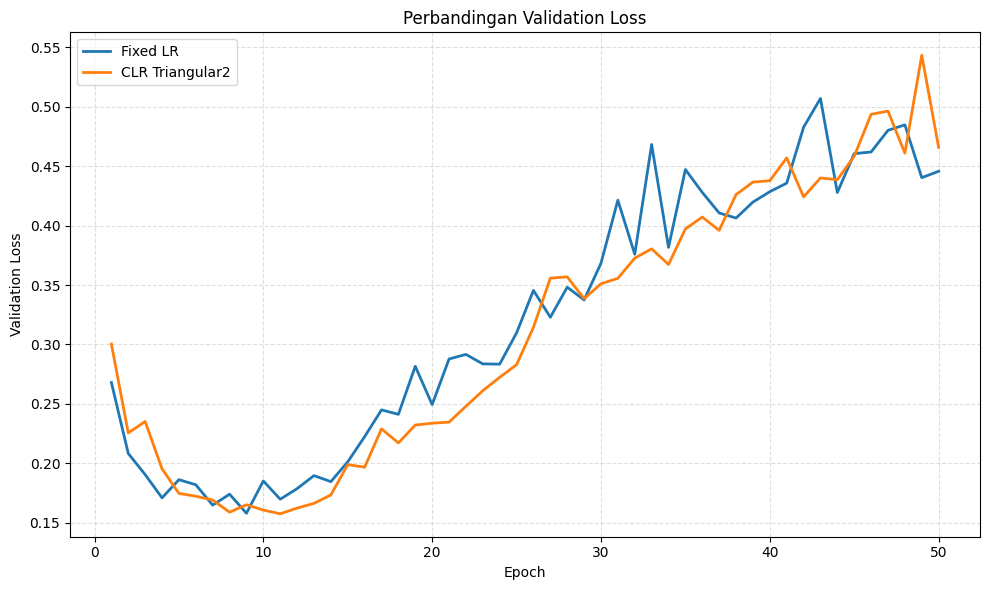

In [47]:
# Membuat array epoch yang digunakan kedua eksperimen.
epochs_common = np.arange(
    1,
    EPOCHS + 1
)

# Membuat figure validation loss.
plt.figure(figsize=(10, 6))

# Menggambar validation loss Fixed LR.
plt.plot(
    epochs_common,
    history_fixed.history["val_loss"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation loss CLR.
plt.plot(
    epochs_common,
    history_clr.history["val_loss"],
    label="CLR Triangular2",
    linewidth=2
)

# Memberikan label sumbu X.
plt.xlabel(
    "Epoch"
)

# Memberikan label sumbu Y.
plt.ylabel(
    "Validation Loss"
)

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Loss"
)

# Menampilkan legenda.
plt.legend()

# Menampilkan grid.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Perbandingan Validation Accuracy

Validation accuracy dibandingkan untuk melihat perkembangan kemampuan klasifikasi kedua model selama proses pelatihan.

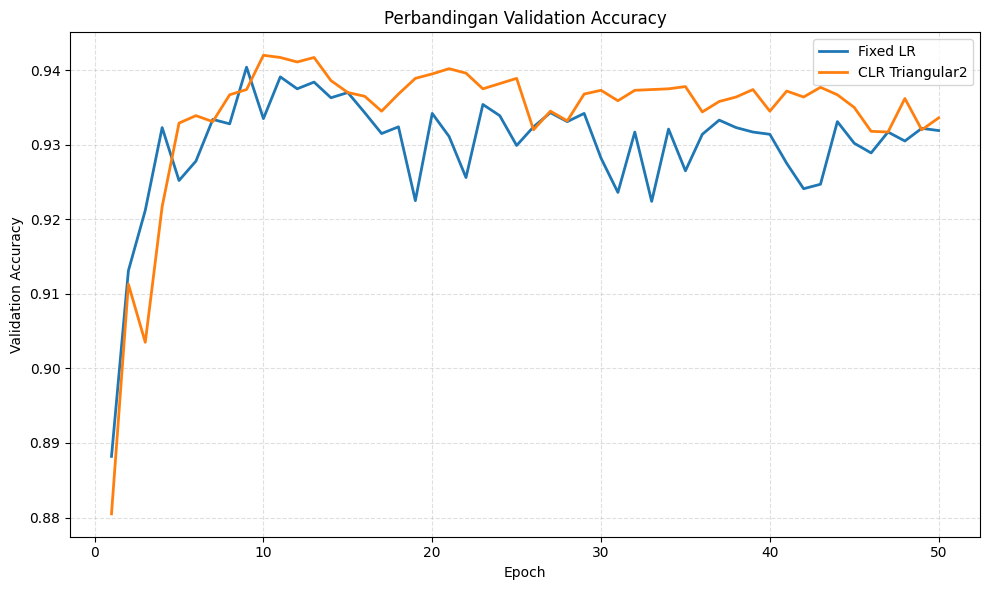

In [40]:
# Membuat figure validation accuracy.
plt.figure(figsize=(10, 6))

# Menggambar validation accuracy Fixed LR.
plt.plot(
    epochs_common,
    history_fixed.history["val_accuracy"],
    label="Fixed LR",
    linewidth=2
)

# Menggambar validation accuracy CLR.
plt.plot(
    epochs_common,
    history_clr.history["val_accuracy"],
    label="CLR Triangular2",
    linewidth=2
)

# Memberikan label sumbu X.
plt.xlabel(
    "Epoch"
)

# Memberikan label sumbu Y.
plt.ylabel(
    "Validation Accuracy"
)

# Memberikan judul grafik.
plt.title(
    "Perbandingan Validation Accuracy"
)

# Menampilkan legenda.
plt.legend()

# Menampilkan grid.
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

# Merapikan layout.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

## Visualisasi Perbandingan Metrik Testing

Visualisasi digunakan untuk memperlihatkan perbedaan performa akhir Fixed Learning Rate dan CLR Triangular2 pada data testing.

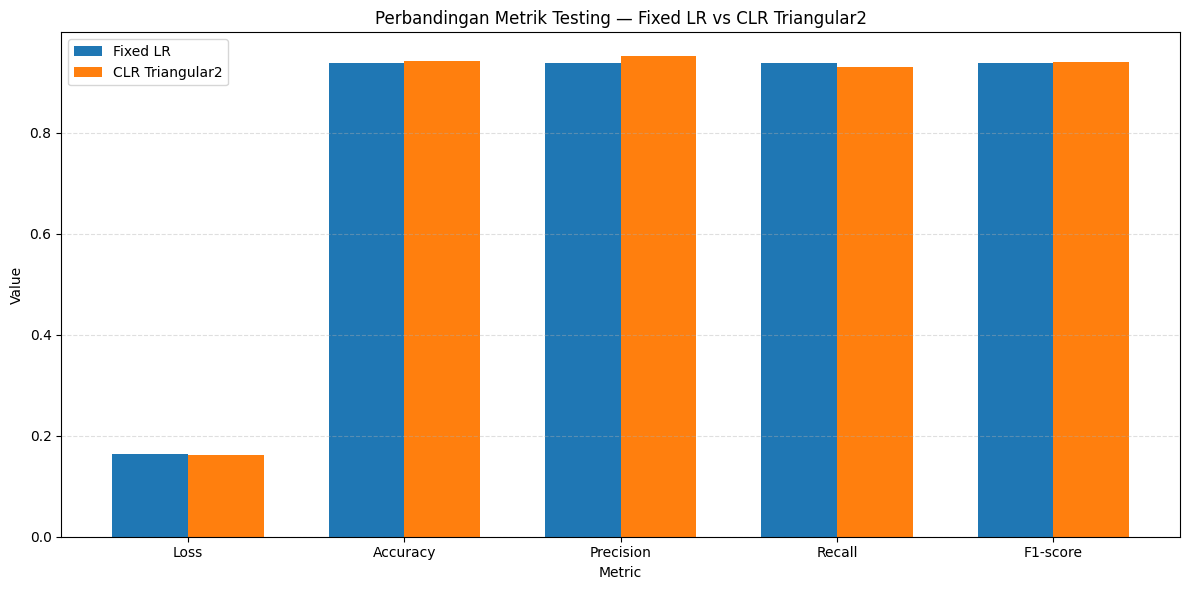

In [41]:
# Menentukan posisi setiap metrik pada sumbu horizontal.
metric_positions = np.arange(
    len(comparison["Metric"])
)

# Menentukan lebar setiap batang.
bar_width = 0.35

# Membuat area grafik perbandingan metrik.
plt.figure(figsize=(12, 6))

# Menggambar metrik Fixed Learning Rate.
plt.bar(
    metric_positions - bar_width / 2,
    comparison["Fixed LR"],
    width=bar_width,
    label="Fixed LR"
)

# Menggambar metrik CLR Triangular2.
plt.bar(
    metric_positions + bar_width / 2,
    comparison["CLR Triangular2"],
    width=bar_width,
    label="CLR Triangular2"
)

# Mengatur posisi label metrik pada sumbu horizontal.
plt.xticks(
    metric_positions,
    comparison["Metric"]
)

# Memberikan label pada sumbu horizontal.
plt.xlabel("Metric")

# Memberikan label pada sumbu vertikal.
plt.ylabel("Value")

# Memberikan judul grafik.
plt.title(
    "Perbandingan Metrik Testing — Fixed LR vs CLR Triangular2"
)

# Menampilkan legend.
plt.legend()

# Menampilkan grid horizontal untuk membantu membaca nilai.
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# Menyesuaikan tata letak grafik.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

# Ringkasan Eksperimen

Ringkasan eksperimen menyatukan konfigurasi utama penelitian, parameter learning rate, epoch terbaik, serta hasil testing dari Fixed Learning Rate dan CLR Triangular2.

In [42]:
# Menyamakan nama epoch terbaik Fixed Learning Rate.
fixed_best_epoch = best_epoch_fixed

# Membuat tabel ringkasan seluruh eksperimen.
experiment_summary = pd.DataFrame({
    "Parameter": [
        "Training images",
        "Validation images",
        "Testing images",
        "Batch size",
        "Epoch maksimum",
        "Fixed learning rate",
        "LRRT start",
        "LRRT end",
        "LRRT epochs",
        "CLR base_lr",
        "CLR max_lr",
        "CLR step_size",
        "Fixed best epoch",
        "CLR best epoch",
        "Fixed test loss",
        "CLR test loss",
        "Fixed test accuracy",
        "CLR test accuracy",
        "Fixed test precision",
        "CLR test precision",
        "Fixed test recall",
        "CLR test recall",
        "Fixed test F1",
        "CLR test F1"
    ],
    "Value": [
        len(train_paths),
        len(val_paths),
        len(test_paths),
        BATCH_SIZE,
        EPOCHS,
        FIXED_LR,
        LRRT_START,
        LRRT_END,
        LRRT_EPOCHS,
        BASE_LR,
        MAX_LR,
        STEP_SIZE,
        fixed_best_epoch,
        clr_best_epoch,
        fixed_eval["Loss"],
        clr_eval["Loss"],
        fixed_eval["Accuracy"],
        clr_eval["Accuracy"],
        fixed_eval["Precision"],
        clr_eval["Precision"],
        fixed_eval["Recall"],
        clr_eval["Recall"],
        fixed_eval["F1-score"],
        clr_eval["F1-score"]
    ]
})

# Menampilkan tabel ringkasan eksperimen.
display(
    experiment_summary
)

# Menyimpan ringkasan eksperimen ke CSV.
experiment_summary.to_csv(
    RESULTS_DIR
    / "experiment_summary.csv",
    index=False
)

# Menampilkan lokasi seluruh hasil eksperimen.
print(
    f"\nSemua hasil eksperimen disimpan di: "
    f"{RESULTS_DIR}"
)

,Parameter,Value
0,Training images,9.000000e+04
1,Validation images,1.000000e+04
2,Testing images,2.000000e+04
3,Batch size,3.200000e+01
4,Epoch maksimum,5.000000e+01
5,Fixed learning rate,1.000000e-03
6,LRRT start,1.000000e-07
7,LRRT end,1.000000e-01
8,LRRT epochs,5.000000e+00
9,CLR base_lr,3.768829e-04



Semua hasil eksperimen disimpan di: /content/results
